# Numerical comparison: M5-LBFGS, L-BFGS (Wolfe) and L-BFGS (Armijo) on CUTEst

## Methods

| Method | Search direction | Line search | Curvature pairs stored |
|---|---|---|---|
| **L-BFGS (Wolfe)** | $d_k = -H_k g_k$ | Moré–Thuente, strong Wolfe ($c_1 = 10^{-4}$, $c_2 = 0.9$) | every pair (Wolfe guarantees $s^\top y > 0$) |
| **L-BFGS (Armijo)** | $d_k = -H_k g_k$ | Armijo backtracking from $\alpha = 1$ ($c_1 = 10^{-4}$, $\rho = 0.5$) | only if $s^\top y \ge 10^{-10} s^\top s$ |
| **M5-LBFGS** | three-stage M5 construction | damping of all three stages from $\alpha = 1$ ($\rho = 0.5$): sufficient descent $-g^\top d \ge c_d\,\alpha\,g^\top H g$ ($c_d = 10^{-4}$) and Armijo ($c_1 = 10^{-4}$) | only if $s^\top y \ge 10^{-10} s^\top s$ |

L-BFGS (Wolfe) is the original method of Liu & Nocedal (*Math. Program.* 45 (1989) 503–528). L-BFGS (Armijo) uses the
same line search as M5-LBFGS, so that the effect of the M5 construction itself can be seen. All methods use memory
$m = 5$ (the usual choice in CUTEst studies) and $H_k^{(0)} = (s^\top y / y^\top y)\,I$, with first step $1/\|g_0\|$.

**Stopping test** (Liu & Nocedal 1989, eq. (2.8)): $\|\nabla f(x_k)\| < 10^{-5}\max(1, \|x_k\|)$.
A run is a **failure** if it reaches 50000 iterations or if its line search (backtracking) fails.

## Test problems — two tests, analysed separately

CUTEst (Gould, Orban, Toint, *Comput. Optim. Appl.* 60 (2015) 545–557): all unconstrained, twice continuously
differentiable problems of variable dimension.

* **Main test** – each problem at its smallest allowed size with $1000 \le n < 5000$ (98 problems; in fact $n \le 2996$).
* **Large test** – each problem at its largest allowed size with $5000 \le n \le 10000$ (66 problems).

Most problems appear in both tests at different sizes, so the two tests are **not merged**: every table and figure is
made for each test separately.
Excluded: FLETCBV2 and MOREBV (the starting point already satisfies the stopping test, because the objectives are
scaled by $h^2$), and FLETCBV3 and INDEF (objective unbounded below).

## Output of the main experiment (every table as `.csv` and `.tex`, every figure as `.pdf` and `.png`)

Every output is made **separately for each test**; the file names end in `_main` or `_large`.

| File | Content |
|---|---|
| `table1_per_problem_*` | for every problem: dimension n, converged (Yes/No), iterations, gradient evaluations and CPU time of each method (NC = not converged) |
| `table1b_final_values_*` | for every problem: final objective value, final gradient norm and status (C/NC) of each method |
| `table2a_convergence_*` | converged, failed, success rate and problems solved only by this method |
| `table_failures_*` | every run that did not converge: problem, n, method, reason, iterations and final gradient norm |
| `table2b_statistics_*` | mean, Q1, median, Q3, M5 better / worse and geometric-mean ratio (problems solved by all three methods) |
| `table2c_summary_*` | compact summary: success, iterations and gradients (mean/median), CPU median [Q1, Q3] |
| `profile_iterations_*`, `profile_gradients_*`, `profile_cpu_*` | Dolan–Moré profiles, one figure each |
| `boxplot_iterations_*`, `boxplot_cpu_*` | box plots of iterations and CPU time |
| `boxplot_ratios_*` | per-problem ratios M5-LBFGS / L-BFGS (Wolfe) |
| `environment.txt` | software versions and machine (for the paper) |

## Additional experiments for the paper (Parts 13-18, run after Parts 1-7)

| Part | Experiment | Output |
|---|---|---|
| 13 | Effect of the memory size, m = 3, 5, 10, 20 (as in Liu & Nocedal 1989) | `table_memory`, `memory_solved_*`, `memory_iterations_*`, `memory_ratios_*` |
| 14 | Instrumented run of the main test (step lengths, trials, timing, histories); same iterates as Part 6 | `instrumented_main.csv`, `histories_main.json` |
| 15 | Behaviour of the damping: share of unit steps, trials per iteration, why trials were rejected | `table_damping`, `damping_alpha_main` |
| 16 | Where the CPU time goes: evaluations vs L-BFGS algebra (as in Liu & Nocedal, Table 7) | `table_time_split`, `time_split_main` |
| 17 | Convergence histories for DIXON3DQ, CHAINWOO, TRIDIA, VAREIGVL | `history_iterations_*`, `history_cpu_*` |
| 18 | Check of our L-BFGS against SciPy's L-BFGS-B (number of iterations) | `scipy_check_main` |
| 19 | Download all results as one zip file | `M5LBFGS_CUTEst_results.zip` |

Every figure is a separate file (`.pdf` for the paper, `.png` at 600 dpi) and is also shown in the notebook.
Parts 13-18 save their results after every problem, so they can be resumed after a disconnection.

Colours: M5-LBFGS red (solid), L-BFGS (Wolfe) blue (solid), L-BFGS (Armijo) green (dash-dot).

**How to run:** open in Google Colab and choose *Run all*. Every problem of both tests is solved by the three
methods with MAX_ITER = 50000 (the large test takes several hours). Results are saved in Google Drive (folder
`M5LBFGS_CUTEst_results`) after every problem; after a disconnection, choose *Run all* again and the computation
continues where it stopped. Parts 12 and 19 download all results as one zip file.


In [1]:
# ============================================================
# Part 1 : Installation (Google Colab, run once, about 5-10 minutes)
# ============================================================
import os, sys, subprocess

def run(cmd):
    r = subprocess.run(cmd, shell=True, capture_output=True, text=True)
    if r.returncode != 0:
        print(r.stderr[-2000:])
        raise RuntimeError(cmd)

ROOT = "/content/cutest"
os.makedirs(ROOT, exist_ok=True)
run("apt-get -qq install -y gfortran > /dev/null")
run(f"{sys.executable} -m pip -q install meson ninja pycutest jinja2")
for repo, folder in [("sifdecode", "sifdecode"), ("cutest", "cutest"), ("SIF", "mastsif")]:
    if not os.path.isdir(f"{ROOT}/{folder}"):
        run(f"git clone -q --depth 1 https://github.com/ralna/{repo}.git {ROOT}/{folder}")
if not os.path.isfile("/usr/local/bin/sifdecoder"):
    run(f"cd {ROOT}/sifdecode && meson setup builddir --buildtype=release "
        f"&& meson compile -C builddir && meson install -C builddir")
if not os.path.isfile("/usr/local/lib/libcutest_double.a"):
    run(f"cd {ROOT}/cutest && meson setup builddir --buildtype=release -Dtests=false "
        f"-Ddefault_library=static && meson compile -C builddir && meson install -C builddir")
os.environ["MASTSIF"] = f"{ROOT}/mastsif"
os.environ["PYCUTEST_CACHE"] = f"{ROOT}/cache"
os.makedirs(os.environ["PYCUTEST_CACHE"], exist_ok=True)
print("Installation finished.")

Installation finished.


In [2]:
# ============================================================
# Part 2 : Settings
# ============================================================
for v in ["OMP_NUM_THREADS", "OPENBLAS_NUM_THREADS", "MKL_NUM_THREADS"]:
    os.environ[v] = "1"                      # one thread for stable CPU times

import math, time, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import pycutest
from scipy.optimize._linesearch import line_search_wolfe1     # More-Thuente line search
warnings.filterwarnings("ignore")

TESTS = ["main", "large"]   # main: n ~ 1000 (smallest size >= 1000);  large: n = 5000 - 10000 (largest size)
                            # the two tests are run and analysed separately

# ---------- results folder ----------
# USE_DRIVE = True keeps the results in Google Drive, so they survive a Colab disconnection.
# Results are saved after every problem; after a disconnection run all cells again and the computation
# continues where it stopped.
USE_DRIVE = True
DRIVE_FOLDER = "/content/drive/MyDrive/M5LBFGS_CUTEst_results"
if USE_DRIVE:
    try:
        from google.colab import drive
        drive.mount("/content/drive")
        RESULTS = DRIVE_FOLDER
    except Exception as err:                 # not in Colab, or Drive not available
        print("Google Drive not used:", err)
        RESULTS = f"{ROOT}/results"
else:
    RESULTS = f"{ROOT}/results"
os.makedirs(RESULTS, exist_ok=True)
os.chdir(RESULTS)
print("Results are saved in", os.getcwd())

TOL = 1e-5           # stopping test of Liu & Nocedal (1989), eq. (2.8)
MAX_ITER = 50000     # maximum number of iterations (the same for every method, problem and memory size)
MEMORY = 5           # L-BFGS memory size m (m = 5, as in most CUTEst studies)
C1 = 1e-4            # sufficient-decrease (Armijo) constant
C_D = 1e-4           # sufficient-descent constant of M5-LBFGS:  -g^T d >= C_D * alpha * g^T H g
C2 = 0.9             # Wolfe curvature constant
RHO = 0.5            # backtracking factor
MAX_BACKTRACK = 60   # maximum number of backtracking trials per iteration
CURV_EPS = 1e-10     # curvature condition of the Armijo methods: s^T y >= CURV_EPS * s^T s
REPEATS = 3          # CPU time = median of 3 runs (for runs shorter than 5 s)

def converged(x, g):
    # Liu & Nocedal (1989), eq. (2.8):  ||g_k|| < 1e-5 * max(1, ||x_k||),  Euclidean norm
    return np.linalg.norm(g) < TOL * max(1.0, np.linalg.norm(x))

# ---------- software versions and machine (write these in the paper) ----------
import platform, scipy, matplotlib
def shell(cmd):
    r = subprocess.run(cmd, shell=True, capture_output=True, text=True)
    return (r.stdout or r.stderr).strip()
def repo_version(folder):
    # commit and date of the cloned CUTEst / SIFDecode / SIF repository (plus the version in meson.build, if any)
    path = f"{ROOT}/{folder}"
    commit = shell(f"git -C {path} log -1 --format='%h (%cs)'")
    meson = shell(f"grep -m1 -oE \"version *: *'[^']+'\" {path}/meson.build 2>/dev/null | grep -oE \"[0-9][0-9.]*\"")
    return f"{meson}, commit {commit}" if meson else f"commit {commit}"
def cpu_model():
    for line in open("/proc/cpuinfo"):
        if line.startswith("model name"):
            return line.split(":", 1)[1].strip()
    return platform.processor()
ram_gb = os.sysconf("SC_PAGE_SIZE") * os.sysconf("SC_PHYS_PAGES") / 1024**3
ENV = {
    "Python":      platform.python_version(),
    "NumPy":       np.__version__,
    "SciPy":       scipy.__version__,
    "pandas":      pd.__version__,
    "Matplotlib":  matplotlib.__version__,
    "PyCUTEst":    pycutest.__version__,
    "CUTEst":      repo_version("cutest"),
    "SIFDecode":   repo_version("sifdecode"),
    "SIF library": repo_version("mastsif"),
    "gfortran":    shell("gfortran -dumpfullversion -dumpversion"),
    "OS":          f"{platform.system()} {platform.release()} ({shell('. /etc/os-release && echo $PRETTY_NAME')})",
    "CPU":         f"{cpu_model()}, {os.cpu_count()} logical cores (1 thread used)",
    "RAM":         f"{ram_gb:.1f} GB",
}
print("Software and machine:")
for k, v in ENV.items():
    print(f"  {k:12s}: {v}")
with open("environment.txt", "w") as fh:
    fh.writelines(f"{k}: {v}\n" for k, v in ENV.items())

print("\nSettings ready. Tests:", TESTS)

Mounted at /content/drive
Results are saved in /content/drive/MyDrive/M5LBFGS_CUTEst_results
Software and machine:
  Python      : 3.13.16
  NumPy       : 2.1.3
  SciPy       : 1.16.3
  pandas      : 2.2.3
  Matplotlib  : 3.10.0
  PyCUTEst    : 1.8.2
  CUTEst      : 2.7.1, commit 7dafe08 (2026-10-01)
  SIFDecode   : 3.1.1, commit 979967c (2026-07-21)
  SIF library : commit 319d16b (2026-09-27)
  gfortran    : 13.3.0
  OS          : Linux 6.6.122+ (Ubuntu 24.04.5 LTS)
  CPU         : Intel(R) Xeon(R) CPU @ 2.20GHz, 2 logical cores (1 thread used)
  RAM         : 12.7 GB

Settings ready. Tests: ['main', 'large']


In [3]:
# ============================================================
# Part 3 : Test problems   (problem -> (size parameter, value))
# ============================================================
PROBLEMS_MAIN = {
    "ARWHEAD": ("N", 1000),   # n = 1000
    "BDQRTIC": ("N", 1000),   # n = 1000
    "BOX": ("N", 1000),   # n = 1000
    "BOXPOWER": ("N", 1000),   # n = 1000
    "BROWNAL": ("N", 1000),   # n = 1000
    "BROYDN3DLS": ("N", 1000),   # n = 1000
    "BROYDN7D": ("N/2", 500),   # n = 1000
    "BROYDNBDLS": ("N", 1000),   # n = 1000
    "BRYBND": ("N", 1000),   # n = 1000
    "CHAINWOO": ("NS", 499),   # n = 1000
    "COSINE": ("N", 1000),   # n = 1000
    "CRAGGLVY": ("M", 499),   # n = 1000
    "CURLY10": ("N", 1000),   # n = 1000
    "CURLY20": ("N", 1000),   # n = 1000
    "CURLY30": ("N", 1000),   # n = 1000
    "CYCLIC3LS": ("N", 1000),   # n = 1002
    "CYCLOOCFLS": ("P", 1000),   # n = 2996
    "DIXMAANA1": ("M", 500),   # n = 1500
    "DIXMAANB": ("M", 500),   # n = 1500
    "DIXMAANC": ("M", 500),   # n = 1500
    "DIXMAAND": ("M", 500),   # n = 1500
    "DIXMAANE1": ("M", 500),   # n = 1500
    "DIXMAANF": ("M", 500),   # n = 1500
    "DIXMAANG": ("M", 500),   # n = 1500
    "DIXMAANH": ("M", 500),   # n = 1500
    "DIXMAANI1": ("M", 500),   # n = 1500
    "DIXMAANJ": ("M", 500),   # n = 1500
    "DIXMAANK": ("M", 500),   # n = 1500
    "DIXMAANL": ("M", 500),   # n = 1500
    "DIXMAANM1": ("M", 500),   # n = 1500
    "DIXMAANN": ("M", 500),   # n = 1500
    "DIXMAANO": ("M", 500),   # n = 1500
    "DIXMAANP": ("M", 500),   # n = 1500
    "DIXON3DQ": ("N", 1000),   # n = 1000
    "DQDRTIC": ("N", 1000),   # n = 1000
    "DQRTIC": ("N", 1000),   # n = 1000
    "EDENSCH": ("N", 2000),   # n = 2000
    "EIGENALS": ("N", 50),   # n = 2550
    "EIGENBLS": ("N", 50),   # n = 2550
    "EIGENCLS": ("M", 25),   # n = 2652
    "ENGVAL1": ("N", 1000),   # n = 1000
    "EXTROSNB": ("N", 1000),   # n = 1000
    "FLETBV3M": ("N", 1000),   # n = 1000
    "FLETCBV2": ("N", 1000),   # n = 1000
    "FLETCBV3": ("N", 1000),   # n = 1000
    "FLETCHBV": ("N", 1000),   # n = 1000
    "FLETCHCR": ("N", 1000),   # n = 1000
    "FMINSRF2": ("P", 32),   # n = 1024
    "FMINSURF": ("P", 32),   # n = 1024
    "FREUROTH": ("N", 1000),   # n = 1000
    "GENHUMPS": ("N", 1000),   # n = 1000
    "INDEF": ("N", 1000),   # n = 1000
    "INDEFM": ("N", 1000),   # n = 1000
    "KSSLS": ("N", 1000),   # n = 1000
    "LIARWHD": ("N", 1000),   # n = 1000
    "MODBEALE": ("N/2", 1000),   # n = 2000
    "MOREBV": ("N", 1000),   # n = 1000
    "MSQRTALS": ("P", 32),   # n = 1024
    "MSQRTBLS": ("P", 32),   # n = 1024
    "NCB20": ("N", 1000),   # n = 1010
    "NCB20B": ("N", 1000),   # n = 1000
    "NONCVXU2": ("N", 1000),   # n = 1000
    "NONCVXUN": ("N", 1000),   # n = 1000
    "NONDIA": ("N", 1000),   # n = 1000
    "NONDQUAR": ("N", 1000),   # n = 1000
    "NONMSQRT": ("P", 32),   # n = 1024
    "OSCIGRAD": ("N", 1000),   # n = 1000
    "PENALTY1": ("N", 1000),   # n = 1000
    "PENALTY2": ("N", 1000),   # n = 1000
    "POWELLSG": ("N", 1000),   # n = 1000
    "POWER": ("N", 1000),   # n = 1000
    "QING": ("N", 1000),   # n = 1000
    "QUARTC": ("N", 1000),   # n = 1000
    "SBRYBND": ("N", 1000),   # n = 1000
    "SCHMVETT": ("N", 1000),   # n = 1000
    "SCOSINE": ("N", 1000),   # n = 1000
    "SCURLY10": ("N", 1000),   # n = 1000
    "SCURLY20": ("N", 1000),   # n = 1000
    "SCURLY30": ("N", 1000),   # n = 1000
    "SENSORS": ("N", 1000),   # n = 1000
    "SINQUAD": ("N", 1000),   # n = 1000
    "SINQUAD2": ("N", 1000),   # n = 1000
    "SPARSINE": ("N", 1000),   # n = 1000
    "SPARSQUR": ("N", 1000),   # n = 1000
    "SPINLS": ("N", 45),   # n = 1082
    "SPMSRTLS": ("M", 334),   # n = 1000
    "SROSENBR": ("N/2", 500),   # n = 1000
    "SSBRYBND": ("N", 1000),   # n = 1000
    "SSCOSINE": ("N", 1000),   # n = 1000
    "STRTCHDV": ("N", 1000),   # n = 1000
    "TESTQUAD": ("N", 1000),   # n = 1000
    "TOINTGSS": ("N", 1000),   # n = 1000
    "TQUARTIC": ("N", 1000),   # n = 1000
    "TRIDIA": ("N", 1000),   # n = 1000
    "TRIGON1": ("N", 1000),   # n = 1000
    "TRIGON2": ("N", 1000),   # n = 1000
    "VAREIGVL": ("N", 999),   # n = 1000
    "WOODS": ("NS", 250),   # n = 1000
    "YATP1CLS": ("N", 50),   # n = 2600
    "YATP1LS": ("N", 50),   # n = 2600
    "YATP2CLS": ("N", 50),   # n = 2600
    "YATP2LS": ("N", 50),   # n = 2600
}

PROBLEMS_LARGE = {
    "ARWHEAD": ("N", 5000),   # n = 5000
    "BDQRTIC": ("N", 5000),   # n = 5000
    "BOX": ("N", 10000),   # n = 10000
    "BOXPOWER": ("N", 10000),   # n = 10000
    "BROYDN3DLS": ("N", 10000),   # n = 10000
    "BROYDN7D": ("N/2", 5000),   # n = 10000
    "BROYDNBDLS": ("N", 10000),   # n = 10000
    "BRYBND": ("N", 10000),   # n = 10000
    "CHAINWOO": ("NS", 4999),   # n = 10000
    "COSINE": ("N", 10000),   # n = 10000
    "CRAGGLVY": ("M", 2499),   # n = 5000
    "DIXMAANA1": ("M", 3000),   # n = 9000
    "DIXMAANB": ("M", 3000),   # n = 9000
    "DIXMAANC": ("M", 3000),   # n = 9000
    "DIXMAAND": ("M", 3000),   # n = 9000
    "DIXMAANE1": ("M", 3000),   # n = 9000
    "DIXMAANF": ("M", 3000),   # n = 9000
    "DIXMAANG": ("M", 3000),   # n = 9000
    "DIXMAANH": ("M", 3000),   # n = 9000
    "DIXMAANI1": ("M", 3000),   # n = 9000
    "DIXMAANJ": ("M", 3000),   # n = 9000
    "DIXMAANK": ("M", 3000),   # n = 9000
    "DIXMAANL": ("M", 3000),   # n = 9000
    "DIXMAANM1": ("M", 3000),   # n = 9000
    "DIXMAANN": ("M", 3000),   # n = 9000
    "DIXMAANO": ("M", 3000),   # n = 9000
    "DIXMAANP": ("M", 3000),   # n = 9000
    "DIXON3DQ": ("N", 10000),   # n = 10000
    "DQDRTIC": ("N", 5000),   # n = 5000
    "DQRTIC": ("N", 5000),   # n = 5000
    "ENGVAL1": ("N", 5000),   # n = 5000
    "FLETBV3M": ("N", 10000),   # n = 10000
    "FLETCBV2": ("N", 10000),   # n = 10000
    "FMINSRF2": ("P", 100),   # n = 10000
    "FMINSURF": ("P", 100),   # n = 10000
    "FREUROTH": ("N", 5000),   # n = 5000
    "GENHUMPS": ("N", 5000),   # n = 5000
    "INDEFM": ("N", 10000),   # n = 10000
    "LIARWHD": ("N", 10000),   # n = 10000
    "MOREBV": ("N", 5000),   # n = 5000
    "NCB20": ("N", 5000),   # n = 5010
    "NCB20B": ("N", 5000),   # n = 5000
    "NONCVXU2": ("N", 10000),   # n = 10000
    "NONCVXUN": ("N", 10000),   # n = 10000
    "NONDIA": ("N", 10000),   # n = 10000
    "NONDQUAR": ("N", 10000),   # n = 10000
    "OSCIGRAD": ("N", 10000),   # n = 10000
    "POWELLSG": ("N", 10000),   # n = 10000
    "POWER": ("N", 10000),   # n = 10000
    "QING": ("N", 10000),   # n = 10000
    "QUARTC": ("N", 10000),   # n = 10000
    "SCHMVETT": ("N", 10000),   # n = 10000
    "SCURLY10": ("N", 10000),   # n = 10000
    "SCURLY20": ("N", 10000),   # n = 10000
    "SCURLY30": ("N", 10000),   # n = 10000
    "SINQUAD": ("N", 10000),   # n = 10000
    "SINQUAD2": ("N", 10000),   # n = 10000
    "SPARSINE": ("N", 10000),   # n = 10000
    "SPARSQUR": ("N", 10000),   # n = 10000
    "SPMSRTLS": ("M", 3334),   # n = 10000
    "SROSENBR": ("N/2", 5000),   # n = 10000
    "SSBRYBND": ("N", 5000),   # n = 5000
    "TESTQUAD": ("N", 5000),   # n = 5000
    "TOINTGSS": ("N", 10000),   # n = 10000
    "TQUARTIC": ("N", 10000),   # n = 10000
    "TRIDIA": ("N", 10000),   # n = 10000
    "VAREIGVL": ("N", 4999),   # n = 5000
    "WOODS": ("NS", 2500),   # n = 10000
}

# Problems left out of the comparison (with the reason, printed below and written in the paper)
EXCLUDE = {
    "FLETCBV2": "starting point already satisfies the stopping test (objective scaled by h^2)",
    "MOREBV":   "starting point already satisfies the stopping test (objective scaled by h^2)",
    "FLETCBV3": "objective unbounded below",
    "INDEF":    "objective unbounded below (its first group is linear: f contains sum_i x_i)",
}

TEST_SETS = {}
for t, problems in [("main", PROBLEMS_MAIN), ("large", PROBLEMS_LARGE)]:
    TEST_SETS[t] = {p: v for p, v in problems.items() if p not in EXCLUDE}
    for p in problems:
        if p in EXCLUDE:
            print(f"{t:5s} test, excluded: {p:10s} ({EXCLUDE[p]})")
for t in TESTS:
    print(f"{t:5s} test: {len(TEST_SETS[t])} problems")

main  test, excluded: FLETCBV2   (starting point already satisfies the stopping test (objective scaled by h^2))
main  test, excluded: FLETCBV3   (objective unbounded below)
main  test, excluded: INDEF      (objective unbounded below (its first group is linear: f contains sum_i x_i))
main  test, excluded: MOREBV     (starting point already satisfies the stopping test (objective scaled by h^2))
large test, excluded: FLETCBV2   (starting point already satisfies the stopping test (objective scaled by h^2))
large test, excluded: MOREBV     (starting point already satisfies the stopping test (objective scaled by h^2))
main  test: 98 problems
large test: 66 problems


In [4]:
# ============================================================
# Part 4 : Tools - evaluation counter and L-BFGS memory
# ============================================================
class Counter:
    # wraps a CUTEst problem and counts function and gradient evaluations
    # timing = True also measures the CPU time spent in function and gradient evaluations (Part 14 only)
    def __init__(self, prob, timing=False):
        self.prob, self.nf, self.ng = prob, 0, 0
        self.timing, self.t_eval = timing, 0.0
        self.f_final, self.gnorm_final = np.nan, np.nan       # f and ||g|| at the last iterate (set by the methods)

    def f(self, x):
        self.nf += 1
        if not self.timing:
            return float(self.prob.obj(x))
        t0 = time.process_time(); v = float(self.prob.obj(x)); self.t_eval += time.process_time() - t0
        return v

    def g(self, x):
        self.ng += 1
        if not self.timing:
            return np.asarray(self.prob.grad(x), dtype=float)
        t0 = time.process_time(); v = np.asarray(self.prob.grad(x), dtype=float)
        self.t_eval += time.process_time() - t0
        return v

    def fg(self, x):
        self.nf += 1
        self.ng += 1
        t0 = time.process_time()
        f, g = self.prob.obj(x, gradient=True)
        if self.timing:
            self.t_eval += time.process_time() - t0
        return float(f), np.asarray(g, dtype=float)


class LBFGSMemory:
    # stores the last m pairs (s, y); apply(v) returns H_k v by the two-loop recursion
    #   check_curvature = True  : store (s, y) only if s^T y >= CURV_EPS * s^T s   (Armijo methods)
    #   check_curvature = False : store every pair (Wolfe guarantees s^T y > 0)    (original L-BFGS)
    def __init__(self, m, gamma0, check_curvature):
        self.m, self.gamma0, self.check = m, gamma0, check_curvature
        self.S, self.Y = [], []

    def update(self, s, y):
        sy = float(s @ y)
        if self.check and not (sy > 0 and sy >= CURV_EPS * float(s @ s)):
            return                                   # pair rejected
        self.S.append(s.copy())
        self.Y.append(y.copy())
        if len(self.S) > self.m:                     # keep only the last m pairs
            self.S.pop(0)
            self.Y.pop(0)

    def apply(self, v):
        if not self.S:                               # no pair yet: H_0 = gamma0 * I
            return self.gamma0 * v
        q, alphas = v.copy(), []
        for s, y in zip(reversed(self.S), reversed(self.Y)):
            a = float(s @ q) / float(y @ s)
            q = q - a * y
            alphas.append(a)
        s, y = self.S[-1], self.Y[-1]
        r = (float(s @ y) / float(y @ y)) * q        # H_k^(0) = (s^T y / y^T y) I
        for (s, y), a in zip(zip(self.S, self.Y), reversed(alphas)):
            r = r + (a - float(y @ r) / float(y @ s)) * s
        return r

print("Tools ready.")

Tools ready.


In [5]:
# ============================================================
# Part 5 : The three methods
# ============================================================
# Each method returns: (number of iterations, converged?, reason, counter)
# counter.f_final and counter.gnorm_final are f and ||g|| at the last iterate.
#   m   : memory size (default MEMORY = 5; Part 13 uses m = 3, 10, 20)
#   log : None in the main experiment. In Part 14 a dict that records, for every iteration, ||g_k||, the
#         CPU time, the accepted step length and the number of trials. Logging does not change the iterates.

def _log_iter(log, g, t_start):
    if log is not None:
        log["gnorm"].append(float(np.linalg.norm(g)))
        log["time"].append(time.process_time() - t_start)

def _final(cnt, f, g):
    # store f and ||g|| of the last iterate in the counter (does not change the iterates)
    cnt.f_final, cnt.gnorm_final = float(f), float(np.linalg.norm(g))
    return cnt

def new_log():
    return {"gnorm": [], "time": [], "alpha": [], "trials": [],
            "sd_reject": 0, "armijo_reject": 0, "nonfinite_reject": 0, "sd_ratio": []}


def lbfgs_wolfe(prob, m=None, log=None):
    # original L-BFGS (Liu & Nocedal 1989): More-Thuente line search, every pair stored
    t_start = time.process_time()
    cnt = Counter(prob, timing=log is not None)
    x = np.array(prob.x0, dtype=float)
    f, g = cnt.fg(x)
    mem = LBFGSMemory(m or MEMORY, 1.0 / max(np.linalg.norm(g), 1e-300), check_curvature=False)
    for k in range(MAX_ITER):
        _log_iter(log, g, t_start)
        if converged(x, g):
            return k, True, "converged", _final(cnt, f, g)
        d = -mem.apply(g)
        alpha, _, _, f_new, _, g_new = line_search_wolfe1(cnt.f, cnt.g, x, d, gfk=g, old_fval=f,
                                                          c1=C1, c2=C2, amax=1e20, amin=1e-20, xtol=1e-16)
        if alpha is None:                            # no Wolfe step found: stop, as in the original code
            return k, False, "line search failed", _final(cnt, f, g)
        if log is not None:
            log["alpha"].append(float(alpha))
        x_new = x + alpha * d
        g_new = cnt.g(x_new) if g_new is None else np.asarray(g_new, dtype=float)
        mem.update(x_new - x, g_new - g)
        x, f, g = x_new, float(f_new), g_new
    _log_iter(log, g, t_start)
    return MAX_ITER, False, "max iterations", _final(cnt, f, g)


def lbfgs_armijo(prob, m=None, log=None):
    # L-BFGS direction with Armijo backtracking from alpha = 1 (same line search as M5-LBFGS)
    t_start = time.process_time()
    cnt = Counter(prob, timing=log is not None)
    x = np.array(prob.x0, dtype=float)
    f, g = cnt.fg(x)
    mem = LBFGSMemory(m or MEMORY, 1.0 / max(np.linalg.norm(g), 1e-300), check_curvature=True)
    for k in range(MAX_ITER):
        _log_iter(log, g, t_start)
        if converged(x, g):
            return k, True, "converged", _final(cnt, f, g)
        d = -mem.apply(g)
        gTd = float(g @ d)
        alpha, accepted = 1.0, False
        for trial in range(1, MAX_BACKTRACK + 1):
            f_new = cnt.f(x + alpha * d)
            if math.isfinite(f_new) and f_new <= f + C1 * alpha * gTd:      # Armijo condition
                accepted = True
                break
            if log is not None:
                log["armijo_reject" if math.isfinite(f_new) else "nonfinite_reject"] += 1
            alpha *= RHO
        if not accepted:
            return k, False, "backtracking failed", _final(cnt, f, g)
        if log is not None:
            log["alpha"].append(alpha); log["trials"].append(trial)
        x_new = x + alpha * d
        g_new = cnt.g(x_new)                         # f(x_new) is already known from the Armijo test
        mem.update(x_new - x, g_new - g)
        x, f, g = x_new, f_new, g_new
    _log_iter(log, g, t_start)
    return MAX_ITER, False, "max iterations", _final(cnt, f, g)


def m5_lbfgs(prob, m=None, log=None):
    # M5-LBFGS: for each trial alpha the complete three-stage construction is recomputed;
    # alpha is accepted if  -g^T d >= C_D * alpha * g^T H g  (sufficient descent)  and the Armijo condition hold
    t_start = time.process_time()
    cnt = Counter(prob, timing=log is not None)
    x = np.array(prob.x0, dtype=float)
    f, g = cnt.fg(x)
    mem = LBFGSMemory(m or MEMORY, 1.0 / max(np.linalg.norm(g), 1e-300), check_curvature=True)
    for k in range(MAX_ITER):
        _log_iter(log, g, t_start)
        if converged(x, g):
            return k, True, "converged", _final(cnt, f, g)
        Hg = mem.apply(g)
        gHg = float(g @ Hg)                                      # g^T H g (for the sufficient-descent test)
        alpha, accepted = 1.0, False
        for trial in range(1, MAX_BACKTRACK + 1):
            y = x - alpha * Hg                                   # stage 1
            Hgy = mem.apply(cnt.g(y))
            z = y - 5.0 * alpha * Hgy                            # stage 2
            Hgz = mem.apply(cnt.g(z))
            x_hat = z - (alpha / 5.0) * (-16.0 * Hgy + Hgz)      # stage 3
            d = x_hat - x
            gTd = float(g @ d)
            if np.all(np.isfinite(d)) and -gTd >= C_D * alpha * gHg:     # sufficient descent
                f_hat = cnt.f(x_hat)
                if math.isfinite(f_hat) and f_hat <= f + C1 * gTd:   # Armijo condition
                    accepted = True
                    break
                if log is not None:
                    log["armijo_reject" if math.isfinite(f_hat) else "nonfinite_reject"] += 1
            elif log is not None:
                log["sd_reject" if np.all(np.isfinite(d)) else "nonfinite_reject"] += 1
            alpha *= RHO
        if not accepted:
            return k, False, "backtracking failed", _final(cnt, f, g)
        if log is not None:
            log["alpha"].append(alpha); log["trials"].append(trial)
            log["sd_ratio"].append(-gTd / (alpha * gHg) if gHg > 0 else np.nan)
        f_new, g_new = f_hat, cnt.g(x_hat)                   # f(x_hat) is already known from the Armijo test
        mem.update(x_hat - x, g_new - g)
        x, f, g = x_hat, f_new, g_new
    _log_iter(log, g, t_start)
    return MAX_ITER, False, "max iterations", _final(cnt, f, g)


METHODS = {"L-BFGS (Wolfe)": lbfgs_wolfe, "L-BFGS (Armijo)": lbfgs_armijo, "M5-LBFGS": m5_lbfgs}
print("Methods ready:", list(METHODS))

Methods ready: ['L-BFGS (Wolfe)', 'L-BFGS (Armijo)', 'M5-LBFGS']


In [6]:
# ============================================================
# Part 6 : Run the three methods on every problem of both tests
# ============================================================
# Every problem of both tests is solved by the three methods with the same settings (Part 2, MAX_ITER = 50000).
# Results are saved after every problem in results_main.csv and results_large.csv; after a disconnection,
# run all cells again: problems already in these files are skipped.

def load_saved(file):
    return pd.read_csv(file).to_dict("records") if os.path.exists(file) else []

def run_test(test):
    file = f"results_{test}.csv"
    rows = load_saved(file)
    done = {(r["Problem"], r["Method"]) for r in rows}
    todo = [p for p in TEST_SETS[test] if not all((p, m) in done for m in METHODS)]
    print(f"\n========== {test} test: {len(TEST_SETS[test])} problems, {len(todo)} still to run ==========")
    for name in todo:
        param, value = TEST_SETS[test][name]
        prob = pycutest.import_problem(name, sifParams={param: value})
        for method, solver in METHODS.items():
            if (name, method) in done:
                continue
            t0 = time.process_time()
            iters, conv, reason, cnt = solver(prob)
            times = [time.process_time() - t0]
            if conv and times[0] < 5.0:                    # repeat short runs for a stable CPU time
                for _ in range(REPEATS - 1):
                    t0 = time.process_time()
                    solver(prob)
                    times.append(time.process_time() - t0)
            rows.append({"Problem": name, "Dimension n": prob.n, "Method": method, "Converged": conv,
                         "Iterations": iters, "Gradient evals": cnt.ng, "Function evals": cnt.nf,
                         "CPU (s)": float(np.median(times)), "Reason": reason,
                         "f final": cnt.f_final, "Gradient norm final": cnt.gnorm_final})
            print(f"{name:12s} n = {prob.n:6d}   {method:15s}  converged = {str(conv):5s}  "
                  f"iterations = {iters:5d}  gradients = {cnt.ng:7d}  CPU = {rows[-1]['CPU (s)']:8.3f} s  ({reason})")
        order = {p: i for i, p in enumerate(TEST_SETS[test])}
        rows.sort(key=lambda r: (order.get(r["Problem"], 10**6), list(METHODS).index(r["Method"])))
        pd.DataFrame(rows).to_csv(file, index=False)
    res = pd.DataFrame(rows)
    res = res[res["Problem"].isin(TEST_SETS[test])]
    solved_by_one = res.groupby("Problem")["Converged"].any()
    print(f"\nAll runs finished: {res['Problem'].nunique()} problems, "
          f"{int((~solved_by_one).sum())} of them solved by no method.")

for test in TESTS:
    run_test(test)


========== main test: 98 problems, 0 still to run ==========

All runs finished: 98 problems, 9 of them solved by no method.

========== large test: 66 problems, 0 still to run ==========

All runs finished: 66 problems, 3 of them solved by no method.


In [7]:
# ============================================================
# Part 7 : Load the results of both tests (each test is analysed separately)
# ============================================================
NAMES = {"main": "Test set I (n < 5000)", "large": "Test set II (n >= 5000)"}
RANGE = {"main": r"smallest size with $n\ge1000$", "large": r"largest size with $5000\le n\le10000$"}
REF = "L-BFGS (Wolfe)"                       # reference method for the ratios

def load_test(test):
    res = pd.read_csv(f"results_{test}.csv")
    res = res[res["Problem"].isin(TEST_SETS[test])]               # excluded problems are dropped
    complete = res.groupby("Problem")["Method"].nunique()
    res = res[res["Problem"].isin(complete[complete == len(METHODS)].index)]   # all three methods finished
    by = {m: res[res["Method"] == m].set_index("Problem").sort_index() for m in METHODS}
    solved = pd.DataFrame({m: by[m]["Converged"].astype(bool) for m in METHODS})
    return {"by": by, "solved": solved,
            "problems": list(solved.index),
            "common": list(solved.index[solved.all(axis=1)]),        # solved by all three methods
            "solvable": list(solved.index[solved.any(axis=1)]),      # solved by at least one method
            "unsolved": list(solved.index[~solved.any(axis=1)])}     # solved by no method

R = {}
for test in TESTS:
    if not os.path.exists(f"results_{test}.csv"):
        print(f"{test}: no results yet (run Part 6)")
        continue
    R[test] = load_test(test)
    d = R[test]
    missing = len(TEST_SETS[test]) - len(d["problems"])
    print(f"{NAMES[test]:10s}: {len(d['problems'])} problems"
          + (f"  ({missing} not finished yet)" if missing else "")
          + f", solved by all three: {len(d['common'])}, solved by none: {len(d['unsolved'])} {d['unsolved']}")

# ---------- helpers for the LaTeX tables (booktabs, as in the paper) ----------
def tex(s):
    return str(s).replace("_", r"\_").replace("%", r"\%").replace("&", r"\&")

def fmt_cpu(v):
    return f"{v:.3f}" if v < 1 else (f"{v:.2f}" if v < 100 else f"{v:.1f}")

def save_tex(name, text):
    with open(name, "w") as fh:
        fh.write(text)

# ---------- figure style used by all figures (Parts 10-19) ----------
# Every figure is a separate file: .pdf (vector, for the paper) and .png (600 dpi).
FIG_SIZE    = (6.4, 4.8)   # inches (width, height) of every figure
TITLE_SIZE  = 18           # figure title
LABEL_SIZE  = 18           # axis labels
TICK_SIZE   = 15           # numbers on the axes
LEGEND_SIZE = 15           # legend
LINE_WIDTH  = 2.5          # lines
plt.rcParams.update({"font.family": "STIXGeneral", "mathtext.fontset": "stix",
                     "font.size": TICK_SIZE, "axes.titlesize": TITLE_SIZE, "axes.labelsize": LABEL_SIZE,
                     "xtick.labelsize": TICK_SIZE, "ytick.labelsize": TICK_SIZE,
                     "legend.fontsize": LEGEND_SIZE, "lines.linewidth": LINE_WIDTH,
                     "axes.linewidth": 1.0, "pdf.fonttype": 42, "ps.fonttype": 42})
COLOR = {"L-BFGS (Wolfe)": "tab:blue", "L-BFGS (Armijo)": "tab:green", "M5-LBFGS": "tab:red"}
LINE  = {"L-BFGS (Wolfe)": "-",        "L-BFGS (Armijo)": "-.",        "M5-LBFGS": "-"}
MARK  = {"L-BFGS (Wolfe)": "s",        "L-BFGS (Armijo)": "^",         "M5-LBFGS": "o"}

def finish_axes(ax, title=None, xlabel=None, ylabel=None, legend=None):
    if title:  ax.set_title(title, fontsize=TITLE_SIZE)
    if xlabel: ax.set_xlabel(xlabel, fontsize=LABEL_SIZE)
    if ylabel: ax.set_ylabel(ylabel, fontsize=LABEL_SIZE)
    ax.tick_params(axis="both", labelsize=TICK_SIZE, direction="in", length=5, top=True, right=True)
    ax.grid(True, which="major", alpha=0.3)
    if legend:
        ax.legend(loc=legend, fontsize=LEGEND_SIZE, frameon=True, framealpha=0.95, edgecolor="0.7")

def save_figure(fig, name):
    # saves name.pdf and name.png and shows the figure in the notebook
    fig.tight_layout()
    fig.savefig(f"{name}.pdf", bbox_inches="tight")
    fig.savefig(f"{name}.png", dpi=600, bbox_inches="tight")
    plt.show()
    print(f"Saved {name}.pdf and {name}.png")

Test set I (n < 5000): 98 problems, solved by all three: 84, solved by none: 9 ['NONMSQRT', 'PENALTY2', 'SBRYBND', 'SCOSINE', 'SCURLY10', 'SCURLY20', 'SCURLY30', 'SPINLS', 'SSCOSINE']
Test set II (n >= 5000): 66 problems, solved by all three: 59, solved by none: 3 ['SCURLY10', 'SCURLY20', 'SCURLY30']


In [8]:
# ============================================================
# Part 8 : Table 1 - results for every problem   (one table per test, NC = not converged)
# ============================================================
SHOW_CONVERGED = True      # True: add a column "Converged - method" (Yes / No) for every method

def table1(test):
    by = R[test]["by"]
    t = pd.DataFrame({"Dimension n": by["M5-LBFGS"]["Dimension n"]})
    if SHOW_CONVERGED:
        for m in METHODS:
            t[f"Converged - {m}"] = by[m]["Converged"].astype(bool).map({True: "Yes", False: "No"})
    for col in ["Iterations", "Gradient evals", "CPU (s)"]:
        for m in METHODS:
            v = by[m][col].round(3) if col == "CPU (s)" else by[m][col]
            t[f"{col} - {m}"] = v.where(by[m]["Converged"].astype(bool), "NC")
    return t

pd.set_option("display.max_rows", 200)
pd.set_option("display.width", 250)
for test in R:
    print(f"\nTable 1 - {NAMES[test]} ({len(R[test]['problems'])} problems)   NC = not converged")
    table1_t = table1(test)
    display(table1_t)
    table1_t.to_csv(f"table1_per_problem_{test}.csv")
    save_tex(f"table1_per_problem_{test}.tex", table1_t.to_latex(escape=True))
    print(f"Saved table1_per_problem_{test}.csv and .tex")

# ---------- Table 1b: final objective value and final gradient norm for every problem ----------
# Shows whether the three methods reach the same minimum (as f_final and ||grad f_final|| in Liu & Nocedal).
def table1b(test):
    by = R[test]["by"]
    t = pd.DataFrame({"Dimension n": by["M5-LBFGS"]["Dimension n"]})
    for m in METHODS:
        t[f"f final - {m}"] = by[m]["f final"].map(lambda v: f"{v:.6e}")
    for m in METHODS:
        t[f"||g|| final - {m}"] = by[m]["Gradient norm final"].map(lambda v: f"{v:.2e}")
    for m in METHODS:
        t[f"Status - {m}"] = by[m]["Converged"].astype(bool).map({True: "C", False: "NC"})
    return t

for test in R:
    if "f final" not in R[test]["by"][REF].columns or R[test]["by"][REF]["f final"].isna().any():
        print(f"{NAMES[test]}: final values not available (run Part 6)")
        continue
    print(f"\nTable 1b - {NAMES[test]}: final objective value and final gradient norm   (C = converged, NC = not converged)")
    t1b = table1b(test)
    display(t1b)
    t1b.to_csv(f"table1b_final_values_{test}.csv")
    save_tex(f"table1b_final_values_{test}.tex", t1b.to_latex(escape=True))
    print(f"Saved table1b_final_values_{test}.csv and .tex")


Table 1 - Test set I (n < 5000) (98 problems)   NC = not converged


,Dimension n,Converged - L-BFGS (Wolfe),Converged - L-BFGS (Armijo),Converged - M5-LBFGS,Iterations - L-BFGS (Wolfe),Iterations - L-BFGS (Armijo),Iterations - M5-LBFGS,Gradient evals - L-BFGS (Wolfe),Gradient evals - L-BFGS (Armijo),Gradient evals - M5-LBFGS,CPU (s) - L-BFGS (Wolfe),CPU (s) - L-BFGS (Armijo),CPU (s) - M5-LBFGS
Problem,,,,,,,,,,,,,
ARWHEAD,1000,Yes,Yes,Yes,11,11,7,13,12,22,0.005,0.004,0.006
BDQRTIC,1000,No,Yes,Yes,NC,200,104,NC,201,505,NC,0.087,0.175
BOX,1000,Yes,Yes,Yes,10,10,7,12,11,42,0.003,0.002,0.006
BOXPOWER,1000,Yes,Yes,Yes,32,53,25,47,54,136,0.007,0.009,0.017
BROWNAL,1000,Yes,Yes,Yes,3,3,2,5,4,7,0.027,0.023,0.037
BROYDN3DLS,1000,Yes,Yes,Yes,33,33,15,35,34,60,0.006,0.006,0.008
BROYDN7D,1000,Yes,Yes,Yes,355,357,208,363,358,1239,0.2,0.181,0.32
BROYDNBDLS,1000,Yes,Yes,Yes,31,31,17,33,32,68,0.009,0.008,0.014
BRYBND,1000,Yes,Yes,Yes,31,31,17,33,32,68,0.009,0.008,0.013


Saved table1_per_problem_main.csv and .tex

Table 1 - Test set II (n >= 5000) (66 problems)   NC = not converged


,Dimension n,Converged - L-BFGS (Wolfe),Converged - L-BFGS (Armijo),Converged - M5-LBFGS,Iterations - L-BFGS (Wolfe),Iterations - L-BFGS (Armijo),Iterations - M5-LBFGS,Gradient evals - L-BFGS (Wolfe),Gradient evals - L-BFGS (Armijo),Gradient evals - M5-LBFGS,CPU (s) - L-BFGS (Wolfe),CPU (s) - L-BFGS (Armijo),CPU (s) - M5-LBFGS
Problem,,,,,,,,,,,,,
ARWHEAD,5000,Yes,Yes,Yes,12,11,8,14,12,25,0.008,0.007,0.012
BDQRTIC,5000,No,Yes,Yes,NC,342,214,NC,343,2427,NC,0.825,1.566
BOX,10000,Yes,Yes,Yes,10,10,12,12,11,59,0.018,0.017,0.073
BOXPOWER,10000,Yes,Yes,Yes,45,52,25,55,53,128,0.059,0.067,0.118
BROYDN3DLS,10000,Yes,Yes,Yes,30,34,17,35,35,76,0.033,0.034,0.063
BROYDN7D,10000,Yes,Yes,Yes,3117,3123,1723,3149,3124,10150,9.207,8.149,25.448
BROYDNBDLS,10000,Yes,Yes,Yes,41,74,27,50,75,150,0.174,0.238,0.411
BRYBND,10000,Yes,Yes,Yes,41,74,27,50,75,150,0.088,0.143,0.232
CHAINWOO,10000,Yes,Yes,Yes,423,307,158,467,308,763,0.744,0.806,1.104


Saved table1_per_problem_large.csv and .tex

Table 1b - Test set I (n < 5000): final objective value and final gradient norm   (C = converged, NC = not converged)


,Dimension n,f final - L-BFGS (Wolfe),f final - L-BFGS (Armijo),f final - M5-LBFGS,||g|| final - L-BFGS (Wolfe),||g|| final - L-BFGS (Armijo),||g|| final - M5-LBFGS,Status - L-BFGS (Wolfe),Status - L-BFGS (Armijo),Status - M5-LBFGS
Problem,,,,,,,,,,
ARWHEAD,1000,0.000000e+00,0.000000e+00,0.000000e+00,1.24e-07,2.30e-06,4.29e-06,C,C,C
BDQRTIC,1000,3.983818e+03,3.983818e+03,3.983818e+03,3.94e-04,9.27e-05,5.84e-05,NC,C,C
BOX,1000,-1.773706e+02,-1.773706e+02,-1.773706e+02,6.92e-06,6.94e-06,8.13e-05,C,C,C
BOXPOWER,1000,4.883533e-07,8.782017e-10,7.728718e-09,1.13e-04,1.07e-04,8.62e-05,C,C,C
BROWNAL,1000,3.237639e-11,2.765234e-11,2.947156e-11,3.63e-05,3.33e-05,3.44e-05,C,C,C
BROYDN3DLS,1000,7.125279e-01,7.125279e-01,2.861335e-10,2.04e-04,1.52e-04,1.45e-04,C,C,C
BROYDN7D,1000,3.935836e+02,3.935836e+02,3.841456e+02,1.74e-04,2.02e-04,1.73e-04,C,C,C
BROYDNBDLS,1000,1.083841e-12,1.123319e-12,1.379075e-12,4.80e-06,4.74e-06,8.83e-06,C,C,C
BRYBND,1000,1.083841e-12,1.123319e-12,1.379075e-12,4.80e-06,4.74e-06,8.83e-06,C,C,C


Saved table1b_final_values_main.csv and .tex

Table 1b - Test set II (n >= 5000): final objective value and final gradient norm   (C = converged, NC = not converged)


,Dimension n,f final - L-BFGS (Wolfe),f final - L-BFGS (Armijo),f final - M5-LBFGS,||g|| final - L-BFGS (Wolfe),||g|| final - L-BFGS (Armijo),||g|| final - M5-LBFGS,Status - L-BFGS (Wolfe),Status - L-BFGS (Armijo),Status - M5-LBFGS
Problem,,,,,,,,,,
ARWHEAD,5000,1.221001e-11,2.220002e-12,0.000000e+00,1.37e-04,2.59e-05,2.88e-06,C,C,C
BDQRTIC,5000,2.000626e+04,2.000626e+04,2.000626e+04,9.66e-03,1.49e-04,1.55e-04,NC,C,C
BOX,10000,-1.864538e+03,-1.864538e+03,-1.864538e+03,1.05e-05,1.05e-05,1.78e-08,C,C,C
BOXPOWER,10000,6.904833e-09,3.817113e-09,1.714007e-08,1.08e-04,1.54e-04,2.45e-04,C,C,C
BROYDN3DLS,10000,7.125279e-01,7.125279e-01,1.164509e-10,6.93e-04,5.48e-04,1.01e-04,C,C,C
BROYDN7D,10000,3.980096e+03,3.980096e+03,3.770901e+03,5.51e-04,6.19e-04,4.70e-04,C,C,C
BROYDNBDLS,10000,7.834771e-13,1.407958e-12,3.796587e-14,5.10e-06,6.02e-06,7.13e-07,C,C,C
BRYBND,10000,7.834771e-13,1.407958e-12,3.796587e-14,5.10e-06,6.02e-06,7.13e-07,C,C,C
CHAINWOO,10000,7.762081e+00,1.656067e+01,2.384246e+01,9.49e-04,8.75e-04,8.21e-04,C,C,C


Saved table1b_final_values_large.csv and .tex


In [9]:
# ============================================================
# Part 9 : Table 2 - (a) convergence summary, failures, (b) statistical summary   (one set per test)
# ============================================================
pd.set_option("display.float_format", lambda v: f"{v:.4g}")

def table2(test):
    d = R[test]
    by, solved, common = d["by"], d["solved"], d["common"]
    TOTAL = len(d["problems"])
    print("=" * 90)
    print(f"{NAMES[test].upper()}")
    print(f"Problems in the test set          : {TOTAL}")
    print(f"Solved by all three methods       : {len(common)}")
    print(f"Solved by at least one method     : {len(d['solvable'])}")
    print(f"Solved by no method               : {len(d['unsolved'])}  {d['unsolved']}")
    print("=" * 90)

    # ---------- (a) convergence summary over ALL problems of the test set ----------
    conv_rows = []
    for m in METHODS:
        r = by[m]
        failed = sorted(r.index[~solved[m]])
        others = [o for o in METHODS if o != m]
        only = sorted(solved.index[solved[m] & ~solved[others].any(axis=1)])
        conv_rows.append({"Method": m, "Problems": TOTAL, "Converged": int(solved[m].sum()),
                          "Failed": len(failed), "Success rate (%)": round(100 * solved[m].mean(), 1),
                          "Solved only by this method": len(only)})
        print(f"\n{m}: converged {int(solved[m].sum())} of {TOTAL}, failed {len(failed)}")
        for p in failed:
            tag = "  (solved by no method)" if p in d["unsolved"] else ""
            print(f"     failed: {p:12s} (n = {r.loc[p, 'Dimension n']}, {r.loc[p, 'Reason']}){tag}")
        if only:
            print(f"     solved only by {m}: {only}")
    table2a = pd.DataFrame(conv_rows).set_index("Method")
    print()
    display(table2a)

    # ---------- failure table: one row for every run that did not converge ----------
    has_g = "Gradient norm final" in by[REF].columns and not by[REF]["Gradient norm final"].isna().all()
    fail_rows = [{"Problem": p, "n": int(by[m].loc[p, "Dimension n"]), "Method": m, "Reason": by[m].loc[p, "Reason"],
                  "Iterations": int(by[m].loc[p, "Iterations"]),
                  "Final gradient norm": (f"{by[m].loc[p, 'Gradient norm final']:.2e}" if has_g else "")}
                 for p in d["problems"] for m in METHODS if not solved.loc[p, m]]
    table_fail = pd.DataFrame(fail_rows, columns=["Problem", "n", "Method", "Reason", "Iterations", "Final gradient norm"])
    print(f"\nRuns that did not converge: {len(table_fail)}")
    display(table_fail)

    # ---------- (b) statistical summary over the problems solved by all three methods ----------
    print(f"\nStatistical summary over the {len(common)} problems solved by all three methods")
    stat_rows = []
    for col in ["Iterations", "Gradient evals", "CPU (s)"]:
        m5 = by["M5-LBFGS"].loc[common, col].astype(float)
        for m in METHODS:
            v = by[m].loc[common, col].astype(float)
            row = {"Measure": col, "Method": m, "Mean": v.mean(), "Q1": v.quantile(0.25),
                   "Median": v.median(), "Q3": v.quantile(0.75)}
            if m != "M5-LBFGS":                         # M5-LBFGS compared with this method
                row["M5 better"] = int((m5 < v).sum())
                row["M5 worse"] = int((m5 > v).sum())
                row["Ratio M5 / method"] = float(np.exp(np.mean(np.log(np.maximum(m5, 1e-12) / np.maximum(v, 1e-12)))))
            stat_rows.append(row)
    table2b = pd.DataFrame(stat_rows).set_index(["Measure", "Method"])
    display(table2b.fillna(""))
    print("M5 better / worse : number of problems on which M5-LBFGS needs less / more than that method.")
    print("Ratio M5 / method : geometric mean of (M5-LBFGS / method); a value below 1 favours M5-LBFGS.")

    # ---------- (c) compact summary (one row per method) ----------
    # Success over all problems; medians and the CPU quartiles over the problems solved by all three methods.
    summ = []
    for m in METHODS:
        v = by[m].loc[common]
        cpu = v["CPU (s)"].astype(float)
        row = {"Method": m, "Success": f"{int(solved[m].sum())}/{TOTAL} ({100 * solved[m].mean():.1f}%)",
               "Iterations (mean/median)": f"{v['Iterations'].mean():.1f} / {v['Iterations'].median():g}",
               "Gradients (mean/median)": f"{v['Gradient evals'].mean():.1f} / {v['Gradient evals'].median():g}",
               "CPU (s) median [Q1, Q3]": f"{cpu.median():.3g} [{cpu.quantile(0.25):.3g}, {cpu.quantile(0.75):.3g}]"}
        summ.append(row)
    table2c = pd.DataFrame(summ).set_index("Method")
    print(f"\nSummary: success over all {TOTAL} problems; iterations, gradients and CPU over the "
          f"{len(common)} problems solved by all three methods")
    display(table2c)

    # ---------- save (.csv and .tex) ----------
    table2c.to_csv(f"table2c_summary_{test}.csv")
    save_tex(f"table2c_summary_{test}.tex", table2c.to_latex(escape=True))
    table2a.to_csv(f"table2a_convergence_{test}.csv")
    table_fail.to_csv(f"table_failures_{test}.csv", index=False)
    table2b.to_csv(f"table2b_statistics_{test}.csv")
    save_tex(f"table2a_convergence_{test}.tex", table2a.to_latex(escape=True))
    save_tex(f"table_failures_{test}.tex", table_fail.to_latex(index=False, escape=True))
    save_tex(f"table2b_statistics_{test}.tex",
             table2b.fillna("").to_latex(float_format=lambda v: f"{v:.4g}", escape=True))
    print(f"Saved table2a_convergence_{test}, table_failures_{test}, table2b_statistics_{test} "
          f"and table2c_summary_{test} (.csv and .tex)\n")

for test in R:
    table2(test)

TEST SET I (N < 5000)
Problems in the test set          : 98
Solved by all three methods       : 84
Solved by at least one method     : 89
Solved by no method               : 9  ['NONMSQRT', 'PENALTY2', 'SBRYBND', 'SCOSINE', 'SCURLY10', 'SCURLY20', 'SCURLY30', 'SPINLS', 'SSCOSINE']

L-BFGS (Wolfe): converged 84 of 98, failed 14
     failed: BDQRTIC      (n = 1000, line search failed)
     failed: CURLY10      (n = 1000, line search failed)
     failed: CURLY20      (n = 1000, line search failed)
     failed: CURLY30      (n = 1000, line search failed)
     failed: MODBEALE     (n = 2000, max iterations)
     failed: NONMSQRT     (n = 1024, max iterations)  (solved by no method)
     failed: PENALTY2     (n = 1000, line search failed)  (solved by no method)
     failed: SBRYBND      (n = 1000, max iterations)  (solved by no method)
     failed: SCOSINE      (n = 1000, line search failed)  (solved by no method)
     failed: SCURLY10     (n = 1000, max iterations)  (solved by no method)
 

,Problems,Converged,Failed,Success rate (%),Solved only by this method
Method,,,,,
L-BFGS (Wolfe),98,84,14,85.7,0
L-BFGS (Armijo),98,87,11,88.8,0
M5-LBFGS,98,89,9,90.8,2



Runs that did not converge: 34


,Problem,n,Method,Reason,Iterations,Final gradient norm
0,BDQRTIC,1000,L-BFGS (Wolfe),line search failed,118,3.94e-04
1,CURLY10,1000,L-BFGS (Wolfe),line search failed,8358,1.18e-03
2,CURLY20,1000,L-BFGS (Wolfe),line search failed,8207,1.75e-03
3,CURLY20,1000,L-BFGS (Armijo),max iterations,50000,1.26e-03
4,CURLY30,1000,L-BFGS (Wolfe),line search failed,8221,2.45e-03
5,MODBEALE,2000,L-BFGS (Wolfe),max iterations,50000,1.73e-01
6,MODBEALE,2000,L-BFGS (Armijo),max iterations,50000,4.39e-02
7,NONMSQRT,1024,L-BFGS (Wolfe),max iterations,50000,7.67e-02
8,NONMSQRT,1024,L-BFGS (Armijo),max iterations,50000,1.01e-01
9,NONMSQRT,1024,M5-LBFGS,max iterations,50000,6.33e-01



Statistical summary over the 84 problems solved by all three methods


...


Statistical summary over the 59 problems solved by all three methods


Mean      Q1  Median     Q3 M5 better M5 worse Ratio M5 / method
Measure        Method                                                                           
Iterations     L-BFGS (Wolfe)    810      31     149    556        55        4            0.6163
               L-BFGS (Armijo) 909.3      35     181    637        57        2             0.547
               M5-LBFGS        437.6    22.5     102  315.5                                     
Gradient evals L-BFGS (Wolfe)  883.1      37     176    590         1       58             2.396
               L-BFGS (Armijo) 910.3      36     182    638         0       59             2.394
               M5-LBFGS         2188    81.5     525   1453                                     
CPU (s)        L-BFGS (Wolfe)  1.122 0.03186  0.2345 0.9473         3       56             1.956
               L-BFGS (Armijo) 1.187 0.03923  0.2381 0.8498         1       58              1.89
               M5-LBFGS        2.325 0.08401  0.4705  1.584

M5 better / worse : number of problems on which M5-LBFGS needs less / more than that method.
Ratio M5 / method : geometric mean of (M5-LBFGS / method); a value below 1 favours M5-LBFGS.

Summary: success over all 66 problems; iterations, gradients and CPU over the 59 problems solved by all three methods


,Success,Iterations (mean/median),Gradients (mean/median),"CPU (s) median [Q1, Q3]"
Method,,,,
L-BFGS (Wolfe),60/66 (90.9%),810.0 / 149,883.1 / 176,"0.234 [0.0319, 0.947]"
L-BFGS (Armijo),61/66 (92.4%),909.3 / 181,910.3 / 182,"0.238 [0.0392, 0.85]"
M5-LBFGS,63/66 (95.5%),437.6 / 102,2188.0 / 525,"0.47 [0.084, 1.58]"


Saved table2a_convergence_large, table_failures_large, table2b_statistics_large and table2c_summary_large (.csv and .tex)



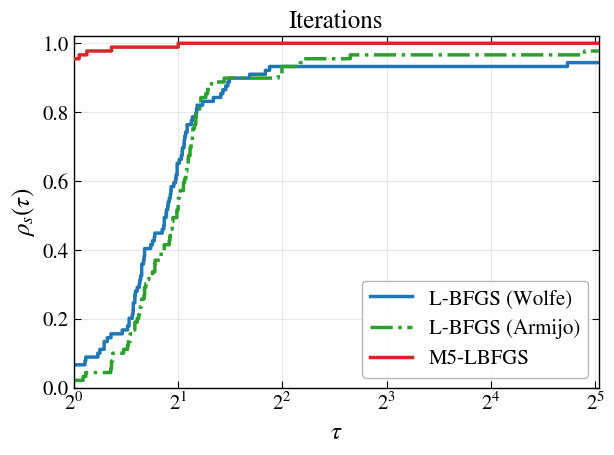

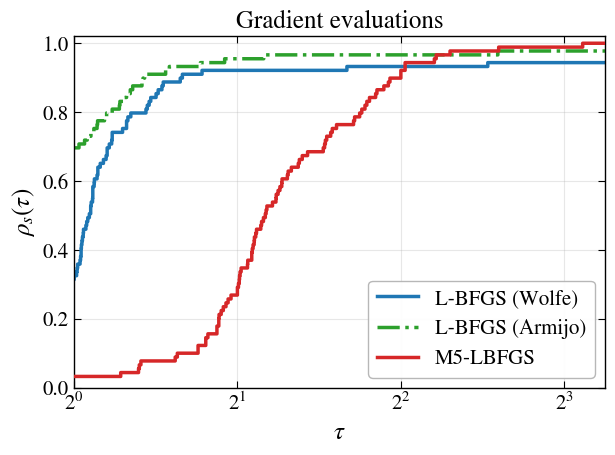

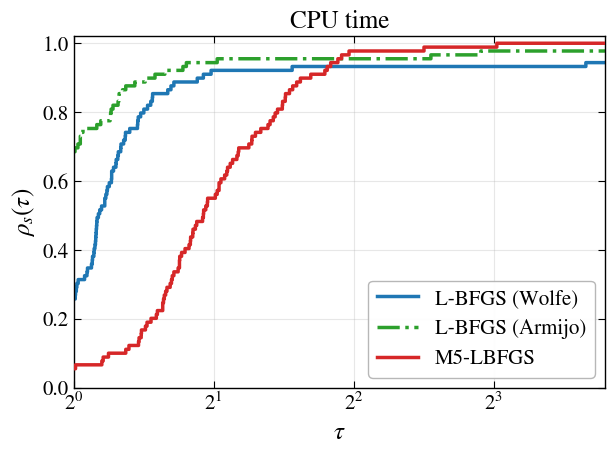

Test set I (n < 5000): profiles over the 89 problems solved by at least one method (9 solved by no method are left out). Saved profile_iterations_main, profile_gradients_main and profile_cpu_main (.pdf and .png)


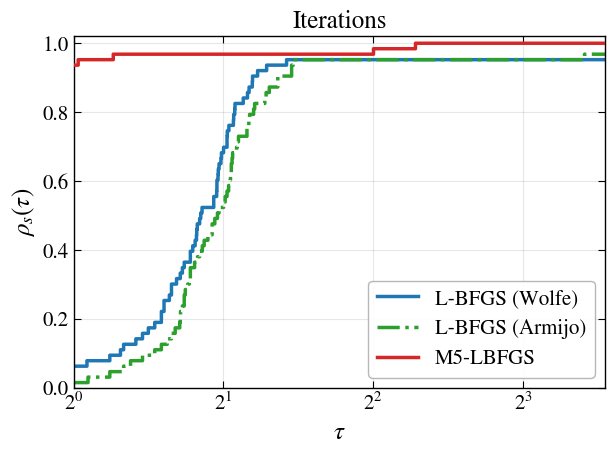

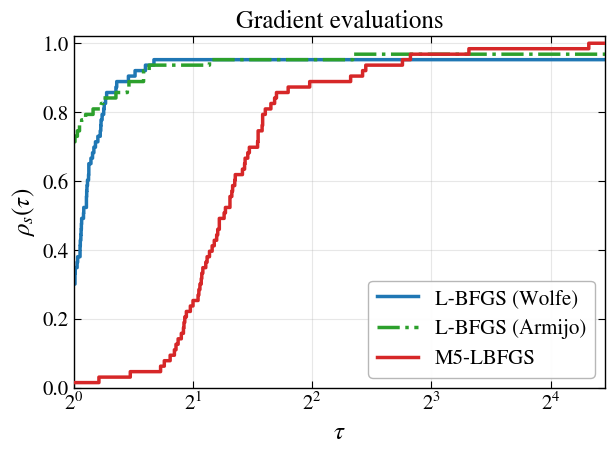

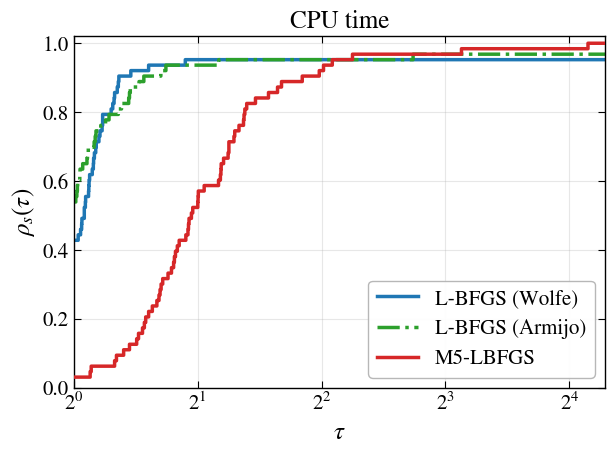

Test set II (n >= 5000): profiles over the 63 problems solved by at least one method (3 solved by no method are left out). Saved profile_iterations_large, profile_gradients_large and profile_cpu_large (.pdf and .png)


In [10]:
# ============================================================
# Part 10 : Dolan-More performance profiles (Dolan & More, Math. Program. 91 (2002) 201-213)
# ============================================================
# rho_s(tau) = fraction of problems on which method s is within a factor tau of the best method.
# A failure counts as infinite cost. Problems solved by no method are left out (they have no best method).
# One separate figure for every measure and every test (6 figures), each saved as
#   .pdf (vector, use this in the paper) and .png (600 dpi).
# In LaTeX:  \includegraphics[width=0.75\textwidth]{profile_iterations_main.pdf}

# ---------- sizes (change here if needed) ----------
FIG_SIZE    = (6.4, 4.8)   # inches (width, height) of every figure
TITLE_SIZE  = 18           # title of the figure, e.g. "Iterations"
LABEL_SIZE  = 18           # axis labels  tau  and  rho_s(tau)
TICK_SIZE   = 15           # numbers on the axes
LEGEND_SIZE = 15           # method names in the legend
LINE_WIDTH  = 2.5          # thickness of the profile lines

plt.rcParams.update({"font.family": "STIXGeneral", "mathtext.fontset": "stix",
                     "font.size": TICK_SIZE, "axes.titlesize": TITLE_SIZE, "axes.labelsize": LABEL_SIZE,
                     "xtick.labelsize": TICK_SIZE, "ytick.labelsize": TICK_SIZE,
                     "legend.fontsize": LEGEND_SIZE, "lines.linewidth": LINE_WIDTH,
                     "axes.linewidth": 1.0, "pdf.fonttype": 42, "ps.fonttype": 42})

COLOR = {"L-BFGS (Wolfe)": "tab:blue", "L-BFGS (Armijo)": "tab:green", "M5-LBFGS": "tab:red"}
LINE  = {"L-BFGS (Wolfe)": "-",        "L-BFGS (Armijo)": "-.",        "M5-LBFGS": "-"}
PANELS = [("Iterations",     "Iterations",           "iterations"),
          ("Gradient evals", "Gradient evaluations", "gradients"),
          ("CPU (s)",        "CPU time",             "cpu")]

def performance_profile(ax, test, column, title):
    by, problems = R[test]["by"], R[test]["solvable"]
    T = np.full((len(problems), len(METHODS)), np.inf)          # cost of method j on problem i
    for i, p in enumerate(problems):
        for j, m in enumerate(METHODS):
            if by[m].loc[p, "Converged"]:
                T[i, j] = max(float(by[m].loc[p, column]), 1e-3 if column == "CPU (s)" else 1.0)
    ratios = T / T.min(axis=1, keepdims=True)                    # performance ratios r_{p,s}
    tau_max = max(2.0, 1.1 * ratios[np.isfinite(ratios)].max())
    taus = np.logspace(0, np.log2(tau_max), 2000, base=2)
    for j, m in enumerate(METHODS):
        ax.step(taus, [(ratios[:, j] <= t).mean() for t in taus], where="post",
                label=m, color=COLOR[m], linestyle=LINE[m], linewidth=LINE_WIDTH,
                zorder=3 if m == "M5-LBFGS" else 2)               # M5-LBFGS drawn on top
    ax.set_xscale("log", base=2)
    ax.set_xlim(1, tau_max)
    ax.set_ylim(0, 1.02)
    ax.set_xlabel(r"$\tau$", fontsize=LABEL_SIZE)
    ax.set_ylabel(r"$\rho_s(\tau)$", fontsize=LABEL_SIZE)
    ax.set_title(title, fontsize=TITLE_SIZE)
    ax.tick_params(axis="both", labelsize=TICK_SIZE, direction="in", length=5, top=True, right=True)
    ax.grid(True, which="major", alpha=0.3)
    ax.legend(loc="lower right", fontsize=LEGEND_SIZE, frameon=True, framealpha=0.95, edgecolor="0.7")

for test in R:
    for column, title, short in PANELS:
        fig, ax = plt.subplots(figsize=FIG_SIZE)
        performance_profile(ax, test, column, title)
        fig.tight_layout()
        fig.savefig(f"profile_{short}_{test}.pdf", bbox_inches="tight")
        fig.savefig(f"profile_{short}_{test}.png", dpi=600, bbox_inches="tight")
        plt.show()
    print(f"{NAMES[test]}: profiles over the {len(R[test]['solvable'])} problems solved by at least one method "
          f"({len(R[test]['unsolved'])} solved by no method are left out). "
          f"Saved profile_iterations_{test}, profile_gradients_{test} and profile_cpu_{test} (.pdf and .png)")


Test set I (n < 5000): box plots over the 84 problems solved by all three methods (CPU times below 1 ms shown as 1 ms)


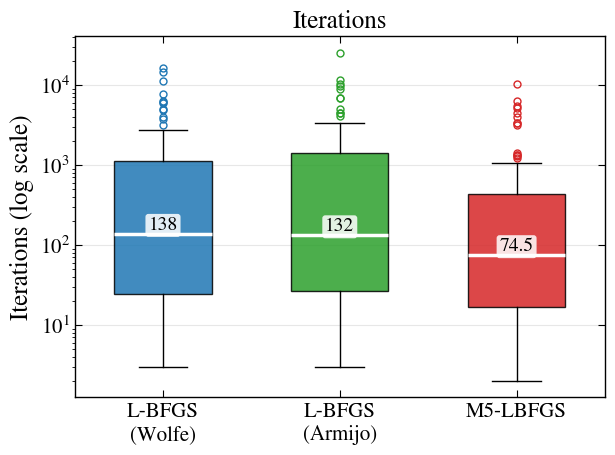

Saved boxplot_iterations_main.pdf and boxplot_iterations_main.png


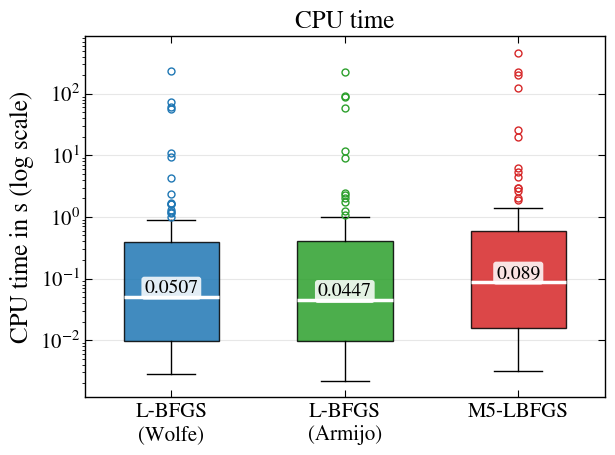

Saved boxplot_cpu_main.pdf and boxplot_cpu_main.png


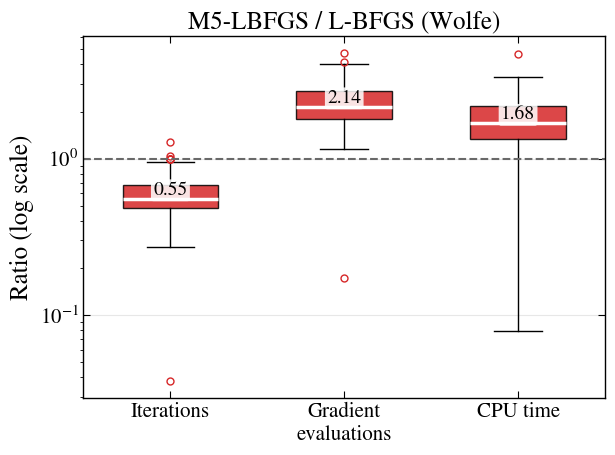

Saved boxplot_ratios_main.pdf and boxplot_ratios_main.png
Below the dashed line M5-LBFGS needs less than L-BFGS (Wolfe).

Test set II (n >= 5000): box plots over the 59 problems solved by all three methods (CPU times below 1 ms shown as 1 ms)


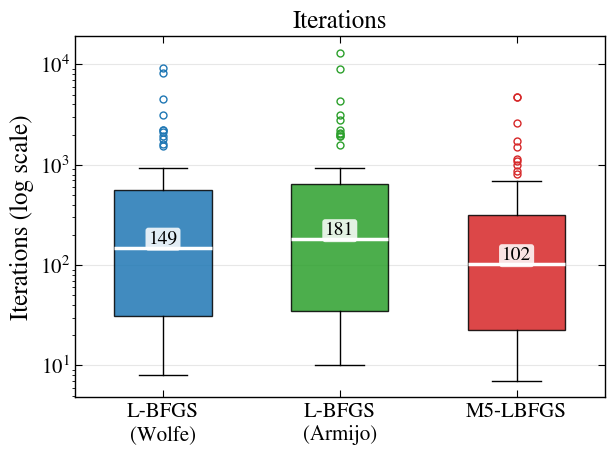

Saved boxplot_iterations_large.pdf and boxplot_iterations_large.png


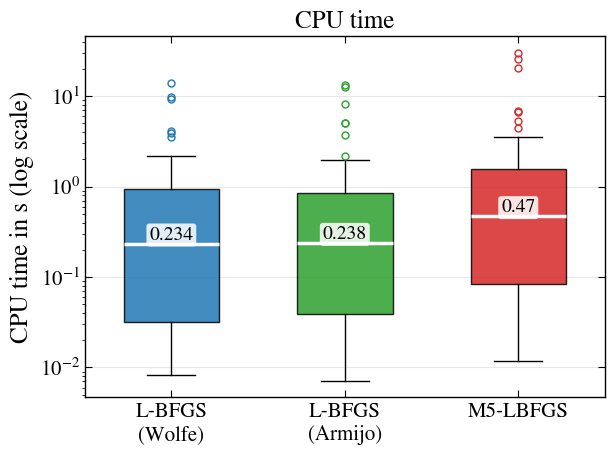

Saved boxplot_cpu_large.pdf and boxplot_cpu_large.png


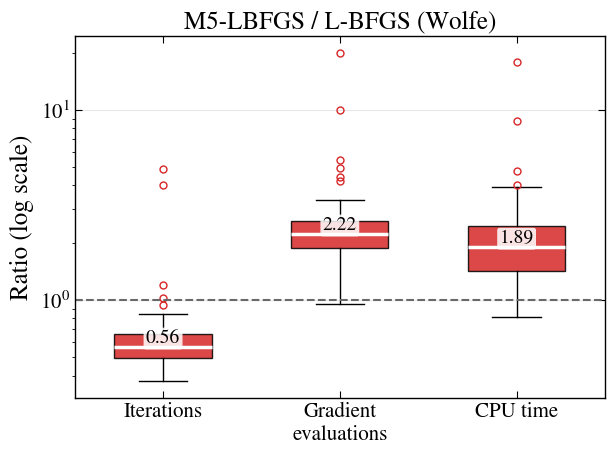

Saved boxplot_ratios_large.pdf and boxplot_ratios_large.png
Below the dashed line M5-LBFGS needs less than L-BFGS (Wolfe).


In [11]:
# ============================================================
# Part 11 : Box plots (problems solved by all three methods), one figure each
# ============================================================
# Box = Q1..Q3, white line = median (value written on the box), whiskers = 1.5 IQR, circles = outliers.
# Logarithmic axis, because iterations and CPU times range over several orders of magnitude.

def method_boxes(test, column, title, ylabel, name):
    by, common = R[test]["by"], R[test]["common"]
    data = [by[m].loc[common, column].astype(float).clip(lower=1e-3).values for m in METHODS]
    fig, ax = plt.subplots(figsize=FIG_SIZE)
    bp = ax.boxplot(data, widths=0.55, patch_artist=True,
                    medianprops=dict(color="white", linewidth=2.5),
                    flierprops=dict(marker="o", markersize=5, markerfacecolor="none"))
    for patch, flier, m in zip(bp["boxes"], bp["fliers"], METHODS):
        patch.set_facecolor(COLOR[m]); patch.set_alpha(0.85)
        flier.set_markeredgecolor(COLOR[m])
    for j, v in enumerate(data, start=1):
        ax.text(j, np.median(v), f"{np.median(v):.3g}", ha="center", va="bottom", fontsize=TICK_SIZE - 1,
                bbox=dict(boxstyle="round,pad=0.15", fc="white", ec="none", alpha=0.85))
    ax.set_xticks(range(1, len(METHODS) + 1))
    ax.set_xticklabels([m.replace(" (", "\n(") for m in METHODS])
    ax.set_yscale("log")
    finish_axes(ax, title=title, ylabel=ylabel)
    ax.grid(False, axis="x")
    save_figure(fig, name)

for test in R:
    print(f"\n{NAMES[test]}: box plots over the {len(R[test]['common'])} problems solved by all three methods "
          f"(CPU times below 1 ms shown as 1 ms)")
    method_boxes(test, "Iterations", "Iterations", "Iterations (log scale)", f"boxplot_iterations_{test}")
    method_boxes(test, "CPU (s)", "CPU time", "CPU time in s (log scale)", f"boxplot_cpu_{test}")

    # per-problem ratios M5-LBFGS / L-BFGS (Wolfe)
    by, common = R[test]["by"], R[test]["common"]
    ratios = [(by["M5-LBFGS"].loc[common, c].astype(float).clip(lower=1e-3)
               / by[REF].loc[common, c].astype(float).clip(lower=1e-3)).values
              for c in ["Iterations", "Gradient evals", "CPU (s)"]]
    fig, ax = plt.subplots(figsize=FIG_SIZE)
    bp = ax.boxplot(ratios, widths=0.55, patch_artist=True,
                    medianprops=dict(color="white", linewidth=2.5),
                    flierprops=dict(marker="o", markersize=5, markerfacecolor="none", markeredgecolor="tab:red"))
    for patch in bp["boxes"]:
        patch.set_facecolor("tab:red"); patch.set_alpha(0.85)
    for j, r in enumerate(ratios, start=1):
        ax.text(j, np.median(r), f"{np.median(r):.2f}", ha="center", va="bottom", fontsize=TICK_SIZE - 1,
                bbox=dict(boxstyle="round,pad=0.12", fc="white", ec="none", alpha=0.85))
    ax.axhline(1.0, color="dimgray", linestyle="--", linewidth=1.5)       # equal cost
    ax.set_xticks([1, 2, 3])
    ax.set_xticklabels(["Iterations", "Gradient\nevaluations", "CPU time"])
    ax.set_yscale("log")
    finish_axes(ax, title="M5-LBFGS / L-BFGS (Wolfe)", ylabel="Ratio (log scale)")
    ax.grid(False, axis="x")
    save_figure(fig, f"boxplot_ratios_{test}")
    print("Below the dashed line M5-LBFGS needs less than L-BFGS (Wolfe).")

In [12]:
# ============================================================
# Part 12 : Download all results as one zip file
# ============================================================
# Works also after a runtime restart: the files are always taken from the results folder in Google Drive
# (or from the results folder of Part 2). The zip is written to /content (not into Drive) and downloaded.
import os, glob, zipfile
try:
    folder = RESULTS                                   # set in Part 2
except NameError:
    folder = "/content/drive/MyDrive/M5LBFGS_CUTEst_results"   # Part 2 not run: use the Drive folder directly
    if not os.path.isdir(folder):
        from google.colab import drive
        drive.mount("/content/drive")
print("Results folder:", folder)

KEEP = (".csv", ".tex", ".pdf", ".png", ".txt", ".json")
files_out = sorted(f for f in glob.glob(os.path.join(folder, "*")) if f.endswith(KEEP))
ZIP = "/content/M5LBFGS_CUTEst_results.zip" if os.path.isdir("/content") else os.path.join(folder, "..", "M5LBFGS_CUTEst_results.zip")
with zipfile.ZipFile(ZIP, "w", zipfile.ZIP_DEFLATED) as z:
    for f in files_out:
        z.write(f, arcname=os.path.basename(f))

kinds = {}
for f in files_out:
    kinds[os.path.splitext(f)[1]] = kinds.get(os.path.splitext(f)[1], 0) + 1
print(f"{len(files_out)} files written to {ZIP}  ({', '.join(f'{v} {k}' for k, v in sorted(kinds.items()))})")
if not files_out:
    print("No result files found: check that the folder above contains results_main.csv.")

try:
    from google.colab import files
    files.download(ZIP)
except Exception as err:
    print("Download it from the Files panel on the left:", ZIP, f"({err})")

Results folder: /content/drive/MyDrive/M5LBFGS_CUTEst_results
92 files written to /content/M5LBFGS_CUTEst_results.zip  (22 .csv, 1 .json, 26 .pdf, 26 .png, 16 .tex, 1 .txt)


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>


========== Test set I (n < 5000), m = 3: 0 of 98 problems still to run ==========

========== Test set I (n < 5000), m = 10: 0 of 98 problems still to run ==========

========== Test set I (n < 5000), m = 20: 0 of 98 problems still to run ==========


,Test,m,Method,Problems,Solved,Solved by all three,Median iterations,Median gradients,Median CPU (s),Ratio M5/method iterations,Ratio M5/method gradients,Ratio M5/method CPU
0,Test set I (n < 5000),3,L-BFGS (Wolfe),98,83,83,151,182,0.04323,0.5429,2.113,1.556
1,Test set I (n < 5000),3,L-BFGS (Armijo),98,88,83,153,154,0.03936,0.5399,2.396,1.942
2,Test set I (n < 5000),3,M5-LBFGS,98,89,83,87,449,0.08554,,,
3,Test set I (n < 5000),5,L-BFGS (Wolfe),98,84,84,137.5,146.5,0.05069,0.5629,2.157,1.667
4,Test set I (n < 5000),5,L-BFGS (Armijo),98,87,84,132,133,0.04474,0.5146,2.246,1.846
5,Test set I (n < 5000),5,M5-LBFGS,98,89,84,74.5,345,0.08896,,,
6,Test set I (n < 5000),10,L-BFGS (Wolfe),98,84,83,130,142,0.06298,0.5489,2.127,1.679
7,Test set I (n < 5000),10,L-BFGS (Armijo),98,86,83,135,136,0.05609,0.5204,2.281,1.932
8,Test set I (n < 5000),10,M5-LBFGS,98,88,83,73,326,0.1067,,,
9,Test set I (n < 5000),20,L-BFGS (Wolfe),98,84,84,131.5,136,0.07609,0.5523,2.123,1.704


Saved table_memory.csv and .tex


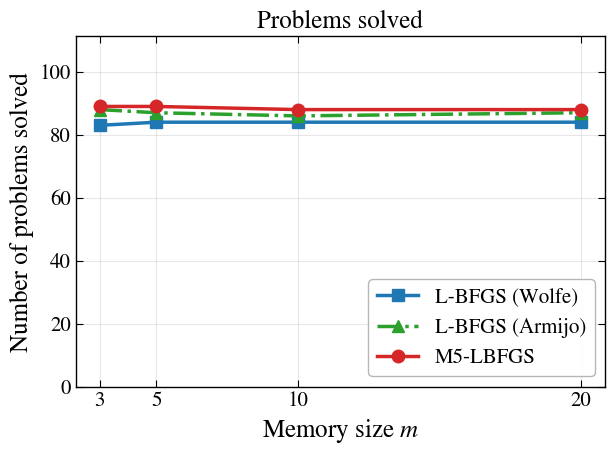

Saved memory_solved_main.pdf and memory_solved_main.png


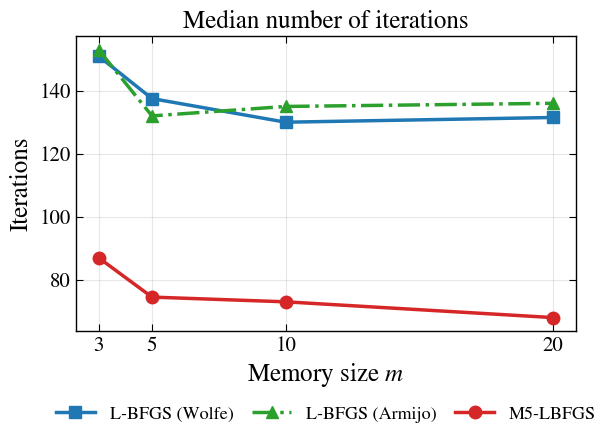

Saved memory_iterations_main.pdf and memory_iterations_main.png


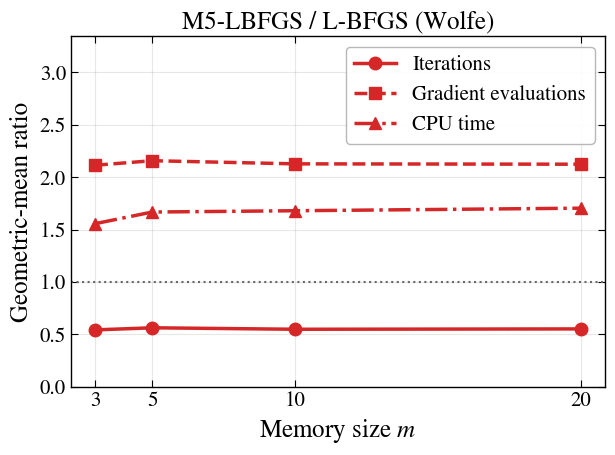

Saved memory_ratios_main.pdf and memory_ratios_main.png


In [13]:
# ============================================================
# Part 13 : Effect of the memory size m   (as in Liu & Nocedal 1989, Tables 3-6 and 12)
# ============================================================
# The three methods are run again with m = 3, 10, 20 (m = 5 is the main experiment (Part 6)).
# Everything else (problems, stopping test, limits) is unchanged. Results are saved after every
# problem in results_<test>_m<m>.csv, so after a disconnection simply run this cell again.
MEMORY_SIZES = [3, 10, 20]         # m = 5 is taken from Part 6
MEMORY_TESTS = ["main"]            # add "large" for the large test as well (takes much longer)

def run_memory(test, m):
    file = f"results_{test}_m{m}.csv"
    rows = load_saved(file)
    done = {(r["Problem"], r["Method"]) for r in rows}
    todo = [p for p in TEST_SETS[test] if not all((p, meth) in done for meth in METHODS)]
    print(f"\n========== {NAMES[test]}, m = {m}: {len(todo)} of {len(TEST_SETS[test])} problems still to run ==========")
    for name in todo:
        param, value = TEST_SETS[test][name]
        prob = pycutest.import_problem(name, sifParams={param: value})
        for method, solver in METHODS.items():
            if (name, method) in done:
                continue
            t0 = time.process_time()
            iters, conv, reason, cnt = solver(prob, m=m)
            times = [time.process_time() - t0]
            if conv and times[0] < 5.0:                    # repeat short runs for a stable CPU time
                for _ in range(REPEATS - 1):
                    t0 = time.process_time()
                    solver(prob, m=m)
                    times.append(time.process_time() - t0)
            rows.append({"Problem": name, "Dimension n": prob.n, "Method": method, "Converged": conv,
                         "Iterations": iters, "Gradient evals": cnt.ng, "Function evals": cnt.nf,
                         "CPU (s)": float(np.median(times)), "Reason": reason})
            print(f"{name:12s} n = {prob.n:6d}   {method:15s}  converged = {str(conv):5s}  "
                  f"iterations = {iters:5d}  gradients = {cnt.ng:7d}  CPU = {rows[-1]['CPU (s)']:8.3f} s  ({reason})")
        pd.DataFrame(rows).to_csv(file, index=False)

for test in MEMORY_TESTS:
    for m in MEMORY_SIZES:
        run_memory(test, m)

# ---------- summary table: one block per memory size ----------
def load_memory(test, m):
    file = f"results_{test}.csv" if m == MEMORY else f"results_{test}_m{m}.csv"
    res = pd.read_csv(file)
    res = res[res["Problem"].isin(TEST_SETS[test])]
    complete = res.groupby("Problem")["Method"].nunique()
    res = res[res["Problem"].isin(complete[complete == len(METHODS)].index)]
    by = {meth: res[res["Method"] == meth].set_index("Problem").sort_index() for meth in METHODS}
    solved = pd.DataFrame({meth: by[meth]["Converged"].astype(bool) for meth in METHODS})
    return by, solved

def geo(a, b):
    return float(np.exp(np.mean(np.log(np.maximum(a, 1e-12) / np.maximum(b, 1e-12)))))

ALL_M = sorted(MEMORY_SIZES + [MEMORY])
mem_rows = []
for test in MEMORY_TESTS:
    for m in ALL_M:
        by, solved = load_memory(test, m)
        common = solved.index[solved.all(axis=1)]
        for meth in METHODS:
            row = {"Test": NAMES[test], "m": m, "Method": meth, "Problems": len(solved),
                   "Solved": int(solved[meth].sum()), "Solved by all three": len(common),
                   "Median iterations": by[meth].loc[common, "Iterations"].median(),
                   "Median gradients": by[meth].loc[common, "Gradient evals"].median(),
                   "Median CPU (s)": by[meth].loc[common, "CPU (s)"].median()}
            if meth != "M5-LBFGS":
                for col, short in [("Iterations", "iterations"), ("Gradient evals", "gradients"), ("CPU (s)", "CPU")]:
                    row[f"Ratio M5/method {short}"] = geo(by["M5-LBFGS"].loc[common, col].astype(float).values,
                                                          by[meth].loc[common, col].astype(float).values)
            mem_rows.append(row)
table_memory = pd.DataFrame(mem_rows)
pd.set_option("display.float_format", lambda v: f"{v:.4g}")
display(table_memory.fillna(""))
table_memory.to_csv("table_memory.csv", index=False)
save_tex("table_memory.tex", table_memory.fillna("").to_latex(index=False, float_format=lambda v: f"{v:.4g}", escape=True))
print("Saved table_memory.csv and .tex")

# ---------- figures (one per test and measure) ----------
for test in MEMORY_TESTS:
    t = table_memory[table_memory["Test"] == NAMES[test]]
    # (a) number of problems solved
    fig, ax = plt.subplots(figsize=FIG_SIZE)
    for meth in METHODS:
        s = t[t["Method"] == meth]
        ax.plot(s["m"], s["Solved"], color=COLOR[meth], linestyle=LINE[meth], marker=MARK[meth],
                markersize=9, label=meth)
    ax.set_xticks(ALL_M)
    ax.set_ylim(0, 1.25 * t["Solved"].max())
    finish_axes(ax, title="Problems solved", xlabel="Memory size $m$", ylabel="Number of problems solved",
                legend="lower right")
    save_figure(fig, f"memory_solved_{test}")
    # (b) median number of iterations
    fig, ax = plt.subplots(figsize=FIG_SIZE)
    for meth in METHODS:
        s = t[t["Method"] == meth]
        ax.plot(s["m"], s["Median iterations"], color=COLOR[meth], linestyle=LINE[meth], marker=MARK[meth],
                markersize=9, label=meth)
    ax.set_xticks(ALL_M)
    finish_axes(ax, title="Median number of iterations", xlabel="Memory size $m$", ylabel="Iterations")
    ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.2), ncol=3, fontsize=LEGEND_SIZE - 2,
              frameon=False, handlelength=2.2, columnspacing=1.0)   # below the axes: never covers the lines
    save_figure(fig, f"memory_iterations_{test}")
    # (c) ratios M5-LBFGS / L-BFGS (Wolfe)
    s = t[t["Method"] == REF]
    fig, ax = plt.subplots(figsize=FIG_SIZE)
    for col, lab, mk, ls in [("Ratio M5/method iterations", "Iterations", "o", "-"),
                             ("Ratio M5/method gradients", "Gradient evaluations", "s", "--"),
                             ("Ratio M5/method CPU", "CPU time", "^", "-.")]:
        ax.plot(s["m"], s[col], color="tab:red", linestyle=ls, marker=mk, markersize=9, label=lab)
    ax.axhline(1.0, color="dimgray", linestyle=":", linewidth=1.5)
    top = max(s[c].max() for c in ["Ratio M5/method iterations", "Ratio M5/method gradients", "Ratio M5/method CPU"])
    ax.set_ylim(0, 1.55 * top)                                       # room for the legend above the lines
    ax.set_xticks(ALL_M)
    finish_axes(ax, title="M5-LBFGS / L-BFGS (Wolfe)", xlabel="Memory size $m$",
                ylabel="Geometric-mean ratio", legend="upper right")
    save_figure(fig, f"memory_ratios_{test}")

In [14]:
# ============================================================
# Part 14 : Instrumented run (main test, m = 5) for Parts 15-17
# ============================================================
# Every method is run once more on every problem of the main test with logging switched on. The log
# records, for every iteration, ||g_k||, the CPU time, the accepted step length alpha_k and the number of
# trials, and the CPU time spent in function and gradient evaluations. Logging does not change the
# iterates: the iteration counts are compared with Part 6 below. Results are saved after every problem.
import json
INSTR_TEST = "main"
SELECTED = ["DIXON3DQ", "CHAINWOO", "TRIDIA", "VAREIGVL"]     # convergence histories (Part 17)
INSTR_FILE, HIST_FILE = f"instrumented_{INSTR_TEST}.csv", f"histories_{INSTR_TEST}.json"

instr_rows = pd.read_csv(INSTR_FILE).to_dict("records") if os.path.exists(INSTR_FILE) else []
histories = json.load(open(HIST_FILE)) if os.path.exists(HIST_FILE) else {}
done = {(r["Problem"], r["Method"]) for r in instr_rows}
todo = [p for p in TEST_SETS[INSTR_TEST] if not all((p, m) in done for m in METHODS)]
print(f"{NAMES[INSTR_TEST]}: {len(todo)} of {len(TEST_SETS[INSTR_TEST])} problems still to run")
for name in todo:
    param, value = TEST_SETS[INSTR_TEST][name]
    prob = pycutest.import_problem(name, sifParams={param: value})
    for method, solver in METHODS.items():
        if (name, method) in done:
            continue
        log = new_log()
        t0 = time.process_time()
        iters, conv, reason, cnt = solver(prob, log=log)
        total = time.process_time() - t0
        alphas = np.array(log["alpha"], dtype=float)
        jcount = {}                                                  # alpha = RHO^j  ->  count of j
        if method != "L-BFGS (Wolfe)" and len(alphas):
            js = np.round(np.log(alphas) / np.log(RHO)).astype(int)
            for j in js:
                jcount[str(int(j))] = jcount.get(str(int(j)), 0) + 1
        instr_rows.append({"Problem": name, "Dimension n": prob.n, "Method": method, "Converged": conv,
                           "Iterations": iters, "Reason": reason, "Gradient evals": cnt.ng,
                           "Function evals": cnt.nf, "CPU total (s)": total, "CPU evaluations (s)": cnt.t_eval,
                           "Accepted steps": len(alphas), "Unit steps": int(np.sum(alphas == 1.0)),
                           "Trials": int(np.sum(log["trials"])) if log["trials"] else np.nan,
                           "Alpha counts": json.dumps(jcount),
                           "SD rejections": log["sd_reject"], "Armijo rejections": log["armijo_reject"],
                           "Non-finite rejections": log["nonfinite_reject"],
                           "Min SD ratio": float(np.nanmin(log["sd_ratio"])) if log["sd_ratio"] else np.nan})
        if name in SELECTED:
            histories.setdefault(name, {})[method] = {"gnorm": log["gnorm"], "time": log["time"]}
        print(f"{name:12s} {method:15s} converged = {str(conv):5s} iterations = {iters:5d}  "
              f"CPU = {total:8.3f} s (evaluations {cnt.t_eval:7.3f} s)")
    pd.DataFrame(instr_rows).to_csv(INSTR_FILE, index=False)
    json.dump(histories, open(HIST_FILE, "w"))

INSTR = pd.DataFrame(instr_rows)
INSTR = INSTR[INSTR["Problem"].isin(TEST_SETS[INSTR_TEST])]
# check: same iterations as the main experiment (Part 6)
main = pd.concat([R[INSTR_TEST]["by"][m].assign(Method=m) for m in METHODS]).reset_index()
chk = INSTR.merge(main[["Problem", "Method", "Iterations"]], on=["Problem", "Method"], suffixes=("", " (Part 6)"))
same = int((chk["Iterations"] == chk["Iterations (Part 6)"]).sum())
print(f"\nIterations equal to Part 6 in {same} of {len(chk)} runs "
      "(small differences can only come from rounding on a different machine).")
common = R[INSTR_TEST]["common"]                     # problems solved by all three methods (Part 7)
ok = INSTR[INSTR["Problem"].isin(common)]
print(f"Saved {INSTR_FILE} and {HIST_FILE}")

Test set I (n < 5000): 0 of 98 problems still to run

Iterations equal to Part 6 in 294 of 294 runs (small differences can only come from rounding on a different machine).
Saved instrumented_main.csv and histories_main.json


,Problems,Iterations,Unit steps (%),Median per problem unit steps (%),Trials per iteration,Rejected: sufficient descent,Rejected: Armijo,Rejected: not finite,Smallest SD ratio,Gradient evals per iteration
Method,,,,,,,,,,
L-BFGS (Wolfe),84,118811,94.31,93.73,,,,,,
L-BFGS (Armijo),84,132597,95.98,96.84,1.049,0,6431,0,,
M5-LBFGS,84,62720,46.84,55.24,1.922,2210,5.559e+04,22,0.0006752,4.845


Over the 84 problems solved by all three methods. Saved table_damping.csv and .tex
Sufficient-descent constant C_D = 0.0001: the smallest observed ratio shows how far the accepted steps are from this bound.


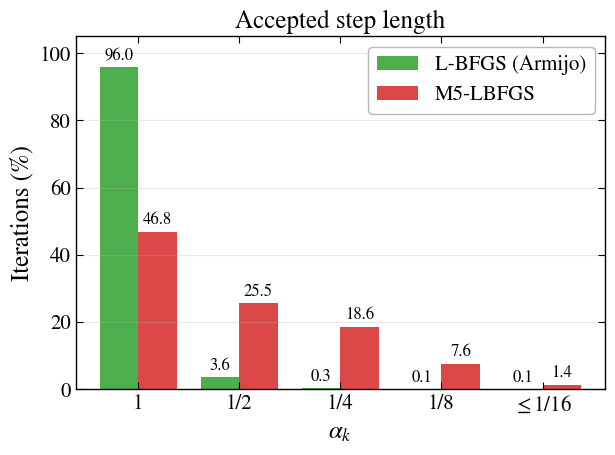

Saved damping_alpha_main.pdf and damping_alpha_main.png


In [15]:
# ============================================================
# Part 15 : Behaviour of the damping (accepted step lengths and trials per iteration)
# ============================================================
# Over the problems of the main test solved by all three methods. For the two backtracking methods:
# share of iterations that accept alpha = 1, mean number of trials per iteration, and the reason why
# trials were rejected. For M5-LBFGS also the smallest value of -g^T d / (alpha g^T H g) over all accepted
# steps (the sufficient-descent test requires >= C_D).
common = R[INSTR_TEST]["common"]
ok = INSTR[INSTR["Problem"].isin(common)]
damp_rows = []
for method in METHODS:
    t = ok[ok["Method"] == method]
    steps = t["Accepted steps"].sum()
    row = {"Method": method, "Problems": len(t), "Iterations": int(steps),
           "Unit steps (%)": 100 * t["Unit steps"].sum() / steps,
           "Median per problem unit steps (%)": float((100 * t["Unit steps"] / t["Accepted steps"].clip(lower=1)).median())}
    if method != "L-BFGS (Wolfe)":
        row.update({"Trials per iteration": t["Trials"].sum() / steps,
                    "Rejected: sufficient descent": int(t["SD rejections"].sum()),
                    "Rejected: Armijo": int(t["Armijo rejections"].sum()),
                    "Rejected: not finite": int(t["Non-finite rejections"].sum())})
    if method == "M5-LBFGS":
        row["Smallest SD ratio"] = float(t["Min SD ratio"].min())
        row["Gradient evals per iteration"] = t["Gradient evals"].sum() / steps
    damp_rows.append(row)
table_damping = pd.DataFrame(damp_rows).set_index("Method")
display(table_damping.fillna(""))
table_damping.to_csv("table_damping.csv")
save_tex("table_damping.tex", table_damping.fillna("").to_latex(float_format=lambda v: f"{v:.4g}", escape=True))
print(f"Over the {len(common)} problems solved by all three methods. Saved table_damping.csv and .tex")
print(f"Sufficient-descent constant C_D = {C_D}: the smallest observed ratio shows how far the accepted "
      "steps are from this bound.")

# ---------- figure: distribution of the accepted step length (Armijo and M5) ----------
labels = ["1", "1/2", "1/4", "1/8", r"$\leq$1/16"]
fig, ax = plt.subplots(figsize=FIG_SIZE)
width = 0.38
for k, method in enumerate(["L-BFGS (Armijo)", "M5-LBFGS"]):
    counts = np.zeros(5)
    for s in ok[ok["Method"] == method]["Alpha counts"]:
        for j, c in json.loads(s).items():
            counts[min(int(j), 4)] += c
    share = 100 * counts / counts.sum()
    pos = np.arange(5) + (k - 0.5) * width
    ax.bar(pos, share, width=width, color=COLOR[method], alpha=0.85, label=method)
    for x, v in zip(pos, share):
        ax.text(x, v + 1, f"{v:.1f}", ha="center", va="bottom", fontsize=TICK_SIZE - 3)
ax.set_xticks(np.arange(5))
ax.set_xticklabels(labels)
ax.set_ylim(0, 105)
finish_axes(ax, title="Accepted step length", xlabel=r"$\alpha_k$", ylabel="Iterations (%)", legend="upper right")
ax.grid(False, axis="x")
save_figure(fig, f"damping_alpha_{INSTR_TEST}")

,Total CPU (s),Evaluations (s),Other (s),Evaluations (%),Gradient evals per iteration,CPU per iteration (ms)
Method,,,,,,
L-BFGS (Wolfe),399.5,368.4,31.08,92.22,1.06,3.363
L-BFGS (Armijo),438,408,30.01,93.15,1.001,3.303
M5-LBFGS,898.9,843.4,55.44,93.83,4.845,14.33


Saved table_time_split.csv and .tex


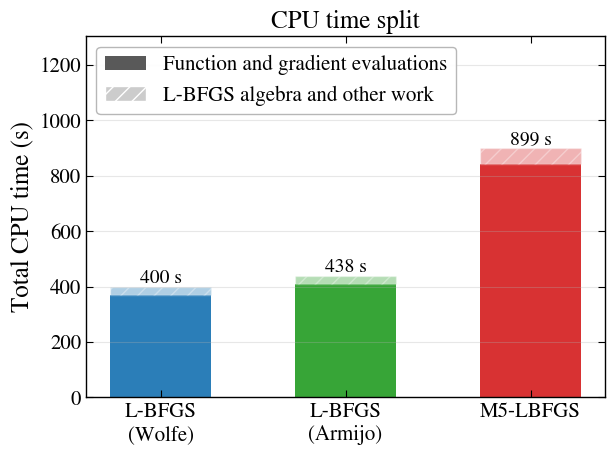

Saved time_split_main.pdf and time_split_main.png


In [16]:
# ============================================================
# Part 16 : Where does the CPU time go?   (as in Liu & Nocedal 1989, Table 7)
# ============================================================
# CPU time of the instrumented run split into (i) function and gradient evaluations and (ii) everything
# else: the L-BFGS two-loop recursions, the vector operations and the line search / damping logic.
# Over the problems of the main test solved by all three methods.
time_rows = []
for method in METHODS:
    t = ok[ok["Method"] == method]
    tot, ev = t["CPU total (s)"].sum(), t["CPU evaluations (s)"].sum()
    steps = t["Accepted steps"].sum()
    time_rows.append({"Method": method, "Total CPU (s)": tot, "Evaluations (s)": ev, "Other (s)": tot - ev,
                      "Evaluations (%)": 100 * ev / tot,
                      "Gradient evals per iteration": t["Gradient evals"].sum() / steps,
                      "CPU per iteration (ms)": 1000 * tot / steps})
table_time = pd.DataFrame(time_rows).set_index("Method")
display(table_time)
table_time.to_csv("table_time_split.csv")
save_tex("table_time_split.tex", table_time.to_latex(float_format=lambda v: f"{v:.4g}", escape=True))
print("Saved table_time_split.csv and .tex")

fig, ax = plt.subplots(figsize=FIG_SIZE)
x = np.arange(len(METHODS))
ev = table_time["Evaluations (s)"].values
other = table_time["Other (s)"].values
from matplotlib.patches import Patch
ax.bar(x, ev, width=0.55, color=[COLOR[m] for m in METHODS], alpha=0.95)
ax.bar(x, other, width=0.55, bottom=ev, color=[COLOR[m] for m in METHODS], alpha=0.35, hatch="//",
       edgecolor="white")
for xi, e, o in zip(x, ev, other):
    ax.text(xi, e + o, f"{e + o:.3g} s", ha="center", va="bottom", fontsize=TICK_SIZE - 1)
ax.set_xticks(x)
ax.set_xticklabels([m.replace(" (", "\n(") for m in METHODS])
ax.set_ylim(0, 1.45 * (ev + other).max())
finish_axes(ax, title="CPU time split", ylabel="Total CPU time (s)")
ax.legend(handles=[Patch(facecolor="0.35", label="Function and gradient evaluations"),
                   Patch(facecolor="0.8", hatch="//", edgecolor="white", label="L-BFGS algebra and other work")],
          loc="upper left", fontsize=LEGEND_SIZE, frameon=True, framealpha=0.95, edgecolor="0.7")
ax.grid(False, axis="x")
save_figure(fig, f"time_split_{INSTR_TEST}")

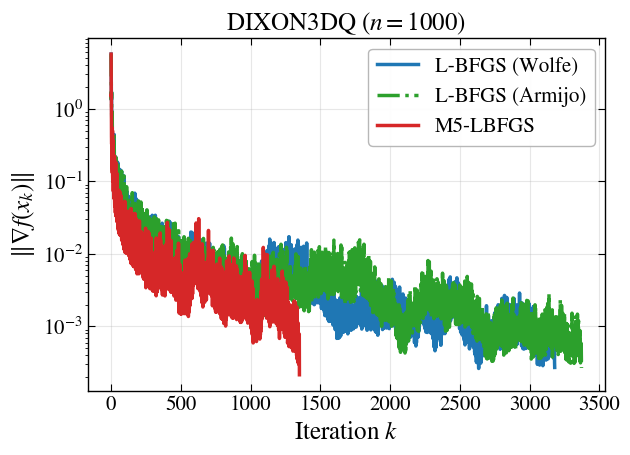

Saved history_iterations_DIXON3DQ.pdf and history_iterations_DIXON3DQ.png


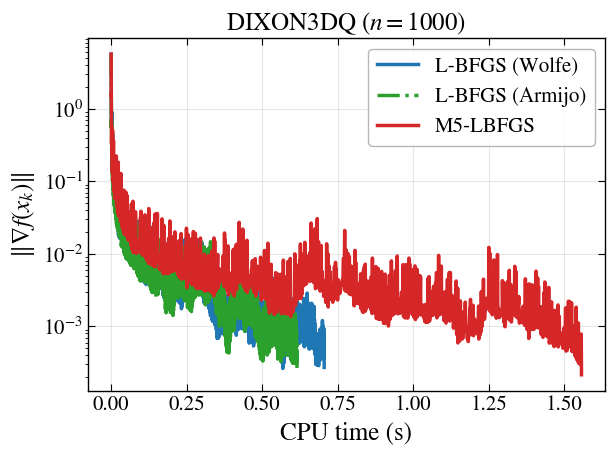

Saved history_cpu_DIXON3DQ.pdf and history_cpu_DIXON3DQ.png


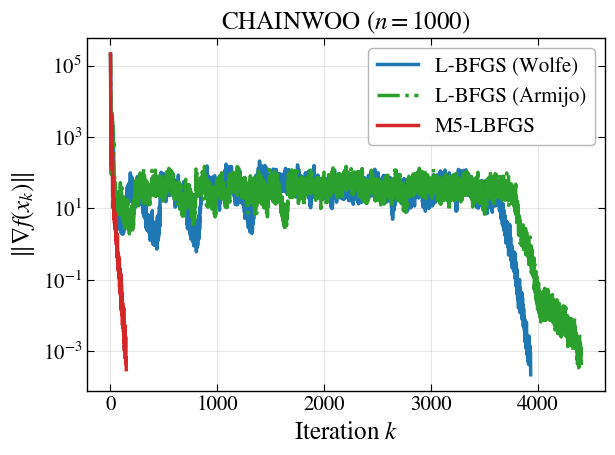

Saved history_iterations_CHAINWOO.pdf and history_iterations_CHAINWOO.png


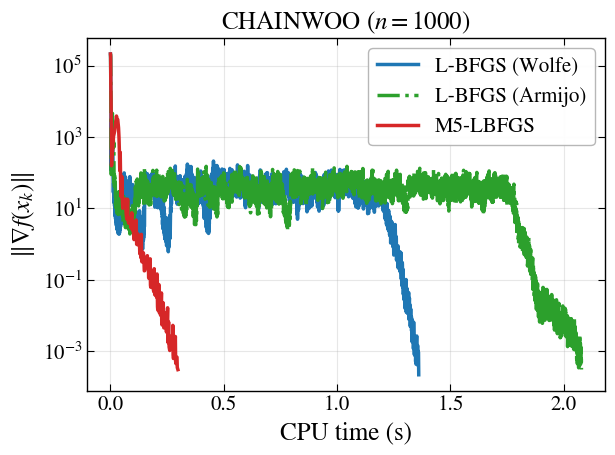

Saved history_cpu_CHAINWOO.pdf and history_cpu_CHAINWOO.png


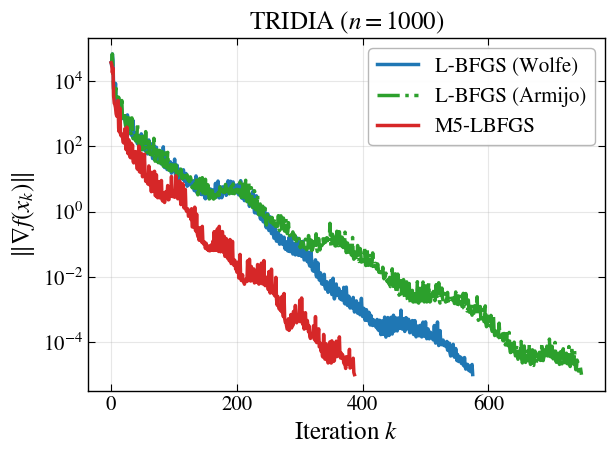

Saved history_iterations_TRIDIA.pdf and history_iterations_TRIDIA.png


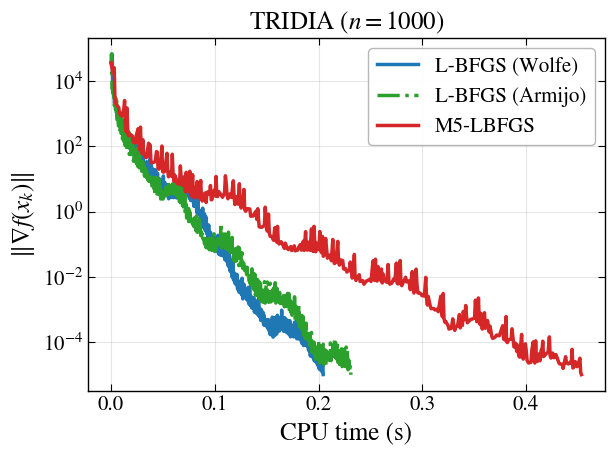

Saved history_cpu_TRIDIA.pdf and history_cpu_TRIDIA.png


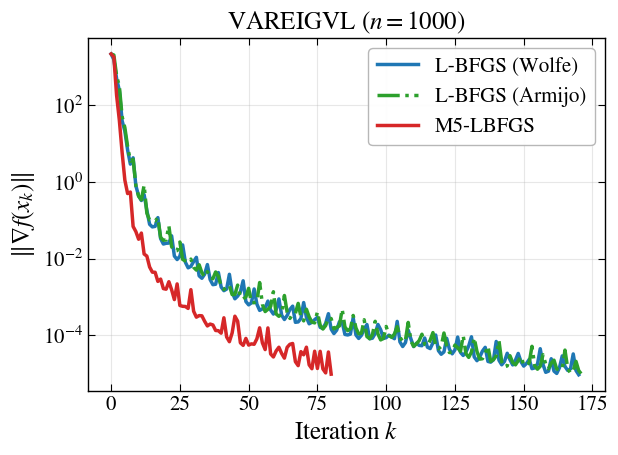

Saved history_iterations_VAREIGVL.pdf and history_iterations_VAREIGVL.png


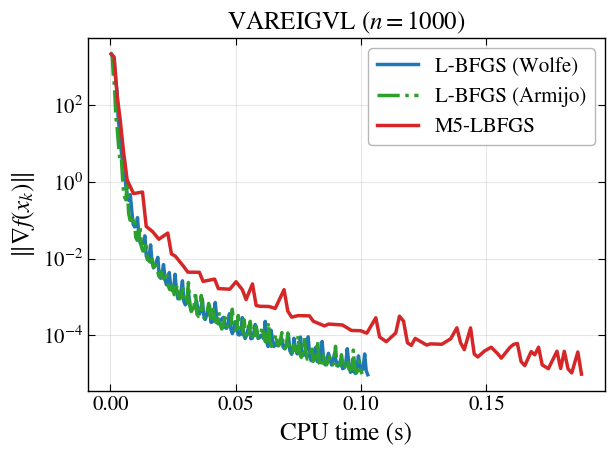

Saved history_cpu_VAREIGVL.pdf and history_cpu_VAREIGVL.png


In [17]:
# ============================================================
# Part 17 : Convergence histories for selected problems
# ============================================================
# ||g_k|| against the iteration number and against the CPU time (log scale), from the instrumented run.
for name in SELECTED:
    if name not in histories:
        print(f"{name}: no history (not in the {INSTR_TEST} test or not run yet)")
        continue
    n = int(INSTR[INSTR["Problem"] == name]["Dimension n"].iloc[0])
    for xkey, xlabel, short in [("iter", "Iteration $k$", "iterations"), ("time", "CPU time (s)", "cpu")]:
        fig, ax = plt.subplots(figsize=FIG_SIZE)
        for method in METHODS:
            h = histories[name].get(method)
            if not h:
                continue
            xs = np.arange(len(h["gnorm"])) if xkey == "iter" else np.array(h["time"])
            ax.semilogy(xs, h["gnorm"], color=COLOR[method], linestyle=LINE[method], label=method)
        finish_axes(ax, title=f"{name} ($n = {n}$)", xlabel=xlabel, ylabel=r"$\|\nabla f(x_k)\|$",
                    legend="upper right")
        save_figure(fig, f"history_{short}_{name}")


SciPy L-BFGS-B converged on 84 of 84 problems solved by our L-BFGS (Wolfe).
Iterations SciPy / ours: geometric mean 1.003, median 1.000, within +-20% on 74 of 84 problems.


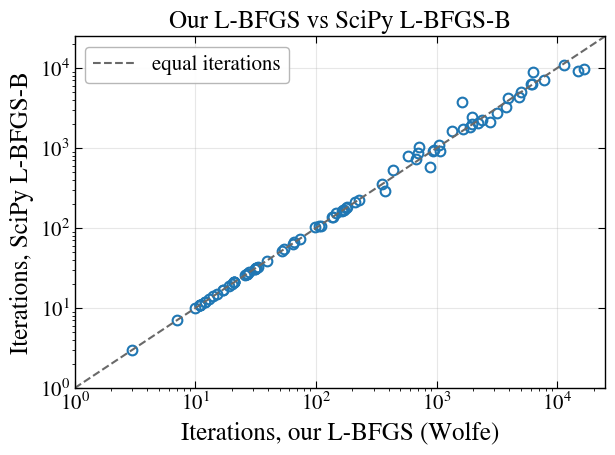

Saved scipy_check_main.pdf and scipy_check_main.png


In [18]:
# ============================================================
# Part 18 : Check of our L-BFGS against the L-BFGS-B code in SciPy
# ============================================================
# SciPy's L-BFGS-B (Byrd, Lu, Nocedal, Zhu) is a widely used Fortran implementation. We run it with the
# same memory (m = 5) and the same stopping test on the main-test problems that our L-BFGS (Wolfe)
# solved, and compare the NUMBER OF ITERATIONS (CPU time is not compared: Fortran vs Python).
# Similar iteration counts show that our L-BFGS implementation is a fair reference.
from scipy.optimize import minimize
SCIPY_FILE = "scipy_check_main.csv"

def scipy_lbfgsb(prob):
    x0 = np.array(prob.x0, dtype=float)
    state = {"it": 0, "conv": False}
    if converged(x0, np.asarray(prob.grad(x0), dtype=float)):
        return 0, True
    def callback(intermediate_result):                       # our stopping test, checked after every iteration
        state["it"] += 1
        x = intermediate_result.x
        if converged(x, np.asarray(prob.grad(x), dtype=float)):
            state["conv"] = True
            raise StopIteration
    minimize(lambda x: prob.obj(x, gradient=True), x0, jac=True, method="L-BFGS-B", callback=callback,
             options=dict(maxcor=MEMORY, maxiter=MAX_ITER, maxfun=10**9, gtol=0.0, ftol=0.0, maxls=60))
    return state["it"], state["conv"]

sc_rows = pd.read_csv(SCIPY_FILE).to_dict("records") if os.path.exists(SCIPY_FILE) else []
done = {r["Problem"] for r in sc_rows}
by_w = R["main"]["by"][REF]
for name in by_w.index[by_w["Converged"].astype(bool)]:
    if name in done:
        continue
    param, value = TEST_SETS["main"][name]
    prob = pycutest.import_problem(name, sifParams={param: value})
    it, conv = scipy_lbfgsb(prob)
    sc_rows.append({"Problem": name, "Dimension n": prob.n, "Iterations L-BFGS (Wolfe)": int(by_w.loc[name, "Iterations"]),
                    "Iterations SciPy L-BFGS-B": it, "SciPy converged": conv})
    print(f"{name:12s} ours = {int(by_w.loc[name, 'Iterations']):6d}   SciPy = {it:6d}  ({'converged' if conv else 'not converged'})")
    pd.DataFrame(sc_rows).to_csv(SCIPY_FILE, index=False)

SC = pd.DataFrame(sc_rows)
both = SC[SC["SciPy converged"].astype(bool)]
ratio = both["Iterations SciPy L-BFGS-B"].clip(lower=1) / both["Iterations L-BFGS (Wolfe)"].clip(lower=1)
print(f"\nSciPy L-BFGS-B converged on {len(both)} of {len(SC)} problems solved by our L-BFGS (Wolfe).")
print(f"Iterations SciPy / ours: geometric mean {np.exp(np.log(ratio).mean()):.3f}, median {ratio.median():.3f}, "
      f"within +-20% on {int(((ratio >= 0.8) & (ratio <= 1.25)).sum())} of {len(both)} problems.")
save_tex("scipy_check_main.tex", SC.to_latex(index=False, escape=True))

fig, ax = plt.subplots(figsize=FIG_SIZE)
ax.loglog(both["Iterations L-BFGS (Wolfe)"].clip(lower=1), both["Iterations SciPy L-BFGS-B"].clip(lower=1),
          "o", color="tab:blue", markersize=7, markerfacecolor="none", markeredgewidth=1.5)
lim = [1, 1.5 * max(both["Iterations L-BFGS (Wolfe)"].max(), both["Iterations SciPy L-BFGS-B"].max())]
ax.plot(lim, lim, color="dimgray", linestyle="--", linewidth=1.5, label="equal iterations")
ax.set_xlim(lim); ax.set_ylim(lim)
finish_axes(ax, title="Our L-BFGS vs SciPy L-BFGS-B", xlabel="Iterations, our L-BFGS (Wolfe)",
            ylabel="Iterations, SciPy L-BFGS-B", legend="upper left")
save_figure(fig, "scipy_check_main")

In [19]:
# ============================================================
# Part 19 : Download all results as one zip file
# ============================================================
# Works also after a runtime restart: the files are always taken from the results folder in Google Drive
# (or from the results folder of Part 2). The zip is written to /content (not into Drive) and downloaded.
import os, glob, zipfile
try:
    folder = RESULTS                                   # set in Part 2
except NameError:
    folder = "/content/drive/MyDrive/M5LBFGS_CUTEst_results"   # Part 2 not run: use the Drive folder directly
    if not os.path.isdir(folder):
        from google.colab import drive
        drive.mount("/content/drive")
print("Results folder:", folder)

KEEP = (".csv", ".tex", ".pdf", ".png", ".txt", ".json")
files_out = sorted(f for f in glob.glob(os.path.join(folder, "*")) if f.endswith(KEEP))
ZIP = "/content/M5LBFGS_CUTEst_results.zip" if os.path.isdir("/content") else os.path.join(folder, "..", "M5LBFGS_CUTEst_results.zip")
with zipfile.ZipFile(ZIP, "w", zipfile.ZIP_DEFLATED) as z:
    for f in files_out:
        z.write(f, arcname=os.path.basename(f))

kinds = {}
for f in files_out:
    kinds[os.path.splitext(f)[1]] = kinds.get(os.path.splitext(f)[1], 0) + 1
print(f"{len(files_out)} files written to {ZIP}  ({', '.join(f'{v} {k}' for k, v in sorted(kinds.items()))})")
if not files_out:
    print("No result files found: check that the folder above contains results_main.csv.")

try:
    from google.colab import files
    files.download(ZIP)
except Exception as err:
    print("Download it from the Files panel on the left:", ZIP, f"({err})")

Results folder: /content/drive/MyDrive/M5LBFGS_CUTEst_results
92 files written to /content/M5LBFGS_CUTEst_results.zip  (22 .csv, 1 .json, 26 .pdf, 26 .png, 16 .tex, 1 .txt)


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>